# Formula 1 Driver Career Analysis

## Research Question

At what age and after how many years in Formula 1 does a driver reach peak performance, and can their early-career results provide indications of their future success?

## Objectives

- Examine how driver performance changes across seasons.
- Identify the age associated with each driver's strongest recorded championship performance.
- Explore the relationship between early-career results and later career outcomes.
- Compare career progression among drivers with records available in the dataset.

## Initial Driver Selection

Twenty drivers were initially selected to represent different Formula 1 eras. The available results dataset covers 1996–2026, so five of the initially selected drivers are not present. The analysis therefore uses the 15 selected drivers who have records in the available dataset.

## Methodology

The analysis uses the project's race results and race calendar datasets. Driver age is calculated from date of birth and race date. Seasonal performance is described using points, wins, podiums, recorded finishing positions, and points-based ranking within each season.

The analysis is limited to the available records. For drivers whose careers began before 1996, the dataset does not contain their complete Formula 1 careers.

## 1. Project Setup and Data Inventory

We first identify the project directory and inspect the available raw and processed data files. This confirms that the notebook is using the expected project structure before loading the datasets.

In [2]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

print("Project root:")
print(PROJECT_ROOT)

print("\nProject folders:")
for folder in ["data/raw", "data/processed", "notebooks"]:
    path = PROJECT_ROOT / folder
    print(f"{folder}: {'Exists' if path.exists() else 'Missing'}")

print("\nAvailable data files:")
for folder in ["data/raw", "data/processed"]:
    path = PROJECT_ROOT / folder

    if path.exists():
        files = [file for file in path.rglob("*") if file.is_file()]
        print(f"\n{folder}: {len(files)} files")

        for file in files[:40]:
            print(" -", file.relative_to(PROJECT_ROOT))

        if len(files) > 40:
            print(f" ... and {len(files) - 40} more files")

Project root:
/mnt/c/Users/sejbi/Downloads/f1-driver-vs-car

Project folders:
data/raw: Exists
data/processed: Exists
notebooks: Exists

Available data files:

data/raw: 2533 files
 - data/raw/fastf1_circuits_raw.csv
 - data/raw/fastf1_corners_raw.csv
 - data/raw/lap_times.csv
 - data/raw/races.csv
 - data/raw/results.csv
 - data/raw/wikipedia_circuits_raw.csv
 - data/raw/fastf1_cache/fastf1_http_cache.sqlite
 - data/raw/laps/1996_round_01.json
 - data/raw/laps/1996_round_02.json
 - data/raw/laps/1996_round_03.json
 - data/raw/laps/1996_round_04.json
 - data/raw/laps/1996_round_05.json
 - data/raw/laps/1996_round_06.json
 - data/raw/laps/1996_round_07.json
 - data/raw/laps/1996_round_08.json
 - data/raw/laps/1996_round_09.json
 - data/raw/laps/1996_round_10.json
 - data/raw/laps/1996_round_11.json
 - data/raw/laps/1996_round_12.json
 - data/raw/laps/1996_round_13.json
 - data/raw/laps/1996_round_14.json
 - data/raw/laps/1996_round_15.json
 - data/raw/laps/1996_round_16.json
 - data/raw

## 2. Data Sources and Processed Files

Next, we locate the CSV files relevant to driver and race analysis and inspect the structure of the processed circuit datasets. This helps distinguish the datasets used directly in the current driver analysis from other project data.

In [3]:
data_dir = PROJECT_ROOT / "data"

print("IMPORTANT DATA FILES:\n")

keywords = [
    "driver", "standing", "result",
    "race", "qualifying", "constructor"
]

for file in sorted(data_dir.rglob("*")):
    if file.is_file() and file.suffix.lower() == ".csv":
        if any(word in file.name.lower() for word in keywords):
            print(file.relative_to(PROJECT_ROOT))

print("\nPROCESSED DATA:\n")

processed_dir = PROJECT_ROOT / "data" / "processed"

for file in sorted(processed_dir.glob("*.csv")):
    df = pd.read_csv(file)
    print(f"\nFile: {file.name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

IMPORTANT DATA FILES:

data/raw/races.csv
data/raw/results.csv

PROCESSED DATA:


File: fastf1_circuits.csv
Shape: (191, 10)
Columns: ['Year', 'Round', 'Event', 'Country', 'Location', 'CircuitKey', 'CornerCount', 'Rotation', 'MarshalLightsCount', 'MarshalSectorsCount']

File: fastf1_corners.csv
Shape: (3119, 7)
Columns: ['Year', 'Event', 'CornerNumber', 'X', 'Y', 'Angle', 'Distance']

File: wikipedia_circuits_cleaned.csv
Shape: (78, 11)
Columns: ['Circuit', 'Type', 'Direction', 'Location', 'Country', 'Turns', 'Grands Prix', 'Season(s)', 'Grands Prix held', 'Circuit_length_km', 'Circuit_length_miles']


## 3. Loading and Understanding the Main Datasets

The current analysis relies on two main CSV files:

- `results.csv`: race-level results, driver information, date of birth, points, finishing position, and constructor information.
- `races.csv`: race dates, event names, circuits, and locations.

We inspect their dimensions, columns, and sample records before carrying out the analysis.

In [4]:
results = pd.read_csv(PROJECT_ROOT / "data/raw/results.csv")
races = pd.read_csv(PROJECT_ROOT / "data/raw/races.csv")

print("RESULTS DATASET")
print("Shape:", results.shape)
print("Columns:", results.columns.tolist())
display(results.head())

print("\nRACES DATASET")
print("Shape:", races.shape)
print("Columns:", races.columns.tolist())
display(races.head())

RESULTS DATASET
Shape: (12390, 28)
Columns: ['season', 'round', 'race_name', 'race_date', 'circuit_id', 'driver_id', 'driver_code', 'driver_first_name', 'driver_last_name', 'driver_date_of_birth', 'driver_nationality', 'constructor_id', 'constructor_name', 'constructor_nationality', 'car_number', 'grid', 'position', 'position_text', 'points', 'laps_completed', 'status', 'race_time', 'race_time_milliseconds', 'fastest_lap_rank', 'fastest_lap_number', 'fastest_lap_time', 'fastest_lap_average_speed', 'fastest_lap_speed_units']


,season,round,race_name,race_date,circuit_id,driver_id,driver_code,driver_first_name,driver_last_name,driver_date_of_birth,...,points,laps_completed,status,race_time,race_time_milliseconds,fastest_lap_rank,fastest_lap_number,fastest_lap_time,fastest_lap_average_speed,fastest_lap_speed_units
0,1996,1,Australian Grand Prix,1996-03-10,albert_park,damon_hill,NaN,Damon,Hill,1960-09-17,...,10.0,58,Finished,1:32:50.400,5570400.0,NaN,NaN,NaN,NaN,NaN
1,1996,1,Australian Grand Prix,1996-03-10,albert_park,villeneuve,VIL,Jacques,Villeneuve,1971-04-09,...,6.0,58,Finished,+38.020,5608420.0,NaN,NaN,NaN,NaN,NaN
2,1996,1,Australian Grand Prix,1996-03-10,albert_park,irvine,NaN,Eddie,Irvine,1965-11-10,...,4.0,58,Finished,+1:02.571,5632971.0,NaN,NaN,NaN,NaN,NaN
3,1996,1,Australian Grand Prix,1996-03-10,albert_park,berger,NaN,Gerhard,Berger,1959-08-27,...,3.0,58,Finished,+1:17.037,5647437.0,NaN,NaN,NaN,NaN,NaN
4,1996,1,Australian Grand Prix,1996-03-10,albert_park,hakkinen,NaN,Mika,Häkkinen,1968-09-28,...,2.0,58,Finished,+1:35.071,5665471.0,NaN,NaN,NaN,NaN,NaN



RACES DATASET
Shape: (591, 13)
Columns: ['season', 'round', 'race_name', 'race_date', 'race_start_time', 'race_url', 'circuit_id', 'circuit_name', 'circuit_url', 'country', 'locality', 'latitude', 'longitude']


,season,round,race_name,race_date,race_start_time,race_url,circuit_id,circuit_name,circuit_url,country,locality,latitude,longitude
0,1996,1,Australian Grand Prix,1996-03-10,NaN,https://en.wikipedia.org/wiki/1996_Australian_...,albert_park,Albert Park Grand Prix Circuit,https://en.wikipedia.org/wiki/Albert_Park_Circuit,Australia,Melbourne,-37.8497,144.9680
1,1996,2,Brazilian Grand Prix,1996-03-31,NaN,https://en.wikipedia.org/wiki/1996_Brazilian_G...,interlagos,Autódromo José Carlos Pace,https://en.wikipedia.org/wiki/Interlagos_Circuit,Brazil,São Paulo,-23.7036,-46.6997
2,1996,3,Argentine Grand Prix,1996-04-07,NaN,https://en.wikipedia.org/wiki/1996_Argentine_G...,galvez,Autódromo Juan y Oscar Gálvez,https://en.wikipedia.org/wiki/Autódromo_Oscar_...,Argentina,Buenos Aires,-34.6943,-58.4593
3,1996,4,European Grand Prix,1996-04-28,NaN,https://en.wikipedia.org/wiki/1996_European_Gr...,nurburgring,Nürburgring,https://en.wikipedia.org/wiki/N%C3%BCrburgring,Germany,Nürburg,50.3356,6.9475
4,1996,5,San Marino Grand Prix,1996-05-05,NaN,https://en.wikipedia.org/wiki/1996_San_Marino_...,imola,Autodromo Enzo e Dino Ferrari,https://en.wikipedia.org/wiki/Imola_Circuit,Italy,Imola,44.3439,11.7167


## 4. Dataset Coverage and Driver Availability

Before selecting the final analysis group, we check the years covered by the results dataset and verify which of the 20 initially selected drivers are present.

The dataset covers 1996–2026. Drivers whose records are not available in this period cannot be included in the current analysis without changing the dataset, which we are not doing.

In [5]:
print("DATASET COVERAGE")
print("First season:", results["season"].min())
print("Last season:", results["season"].max())

print("\nDRIVER COVERAGE")
print("Unique drivers:", results["driver_id"].nunique())

selected_drivers = [
    "Michael Schumacher",
    "Lewis Hamilton",
    "Ayrton Senna",
    "Alain Prost",
    "Sebastian Vettel",
    "Max Verstappen",
    "Fernando Alonso",
    "Niki Lauda",
    "Kimi Räikkönen",
    "Mika Häkkinen",
    "Jenson Button",
    "Nigel Mansell",
    "Nico Rosberg",
    "Jackie Stewart",
    "Charles Leclerc",
    "Lando Norris",
    "Daniel Ricciardo",
    "Felipe Massa",
    "Rubens Barrichello",
    "Juan Pablo Montoya"
]

available_drivers = (
    results[["driver_first_name", "driver_last_name", "driver_id"]]
    .drop_duplicates()
    .copy()
)

available_drivers["full_name"] = (
    available_drivers["driver_first_name"].str.strip()
    + " "
    + available_drivers["driver_last_name"].str.strip()
)

available_drivers["name_key"] = (
    available_drivers["full_name"].str.casefold()
)

selected_name_keys = {name.casefold() for name in selected_drivers}

available_selected_drivers = available_drivers[
    available_drivers["name_key"].isin(selected_name_keys)
].copy()

selected_driver_names = (
    available_selected_drivers["full_name"].drop_duplicates().tolist()
)

print("\nSELECTED DRIVER AVAILABILITY")
for driver in selected_drivers:
    found = driver.casefold() in set(available_selected_drivers["name_key"])
    print(f"{driver}: {'FOUND' if found else 'NOT FOUND'}")

print(
    "\nAvailable selected drivers:",
    len(available_selected_drivers["driver_id"].unique())
)

DATASET COVERAGE
First season: 1996
Last season: 2026

DRIVER COVERAGE
Unique drivers: 149

SELECTED DRIVER AVAILABILITY
Michael Schumacher: FOUND
Lewis Hamilton: FOUND
Ayrton Senna: NOT FOUND
Alain Prost: NOT FOUND
Sebastian Vettel: FOUND
Max Verstappen: FOUND
Fernando Alonso: FOUND
Niki Lauda: NOT FOUND
Kimi Räikkönen: FOUND
Mika Häkkinen: FOUND
Jenson Button: FOUND
Nigel Mansell: NOT FOUND
Nico Rosberg: FOUND
Jackie Stewart: NOT FOUND
Charles Leclerc: FOUND
Lando Norris: FOUND
Daniel Ricciardo: FOUND
Felipe Massa: FOUND
Rubens Barrichello: FOUND
Juan Pablo Montoya: FOUND

Available selected drivers: 15


## 5. Driver Selection and Career Overview

Fifteen of the 20 initially selected drivers have records in the dataset. We retain those 15 drivers and summarize the career information available for each one.

The first and last seasons shown below refer to the first and last seasons recorded in this dataset. They do not necessarily represent the driver's actual Formula 1 debut or retirement year. The number of seasons counts distinct seasons with records, not necessarily consecutive years of experience.

In [6]:
selected_driver_ids = available_selected_drivers["driver_id"].drop_duplicates()

selected_results = results[
    results["driver_id"].isin(selected_driver_ids)
].copy()

driver_summary = (
    selected_results.groupby(
        ["driver_id", "driver_first_name", "driver_last_name"]
    )
    .agg(
        first_season=("season", "min"),
        last_season=("season", "max"),
        seasons_with_records=("season", "nunique"),
        race_entries=("race_name", "count"),
        total_points=("points", "sum")
    )
    .reset_index()
)

driver_summary["full_name"] = (
    driver_summary["driver_first_name"] + " "
    + driver_summary["driver_last_name"]
)

driver_summary = driver_summary.sort_values(
    "first_season"
).reset_index(drop=True)

display(
    driver_summary[
        [
            "full_name",
            "first_season",
            "last_season",
            "seasons_with_records",
            "race_entries",
            "total_points"
        ]
    ]
)

print("Number of selected drivers:", driver_summary["driver_id"].nunique())

,full_name,first_season,last_season,seasons_with_records,race_entries,total_points
0,Rubens Barrichello,1996,2011,16,277,626.0
1,Mika Häkkinen,1996,2001,6,99,360.0
2,Michael Schumacher,1996,2012,14,239,1263.0
3,Jenson Button,2000,2017,18,309,1235.0
4,Juan Pablo Montoya,2001,2006,6,95,307.0
5,Kimi Räikkönen,2001,2021,19,352,1873.0
6,Fernando Alonso,2001,2026,23,448,2387.0
7,Felipe Massa,2002,2017,15,271,1167.0
8,Nico Rosberg,2006,2016,11,206,1594.5
9,Sebastian Vettel,2007,2022,16,300,3098.0


Number of selected drivers: 15


## 6. Feature Engineering

### 6.1 Preparing Race-Level Driver Data

In this step, we prepare the selected drivers' race records for analysis. We convert the race date and date of birth into datetime values, calculate each driver's age at the time of every race, and convert the recorded finishing position into a numeric variable.

Age is calculated for each race rather than using a driver's age at the beginning or end of a season. This allows us to calculate a season-level average age in the next step.

The dataset's first available season is not necessarily a driver's actual F1 debut. Therefore, years of experience cannot yet be interpreted as complete career experience for every driver.

In [7]:
driver_results = selected_results.copy()

driver_results["race_date"] = pd.to_datetime(
    driver_results["race_date"],
    errors="coerce"
)

driver_results["driver_date_of_birth"] = pd.to_datetime(
    driver_results["driver_date_of_birth"],
    errors="coerce"
)

driver_results["age_at_race"] = (
    (driver_results["race_date"]
     - driver_results["driver_date_of_birth"]).dt.days
    / 365.2425
)

driver_results["position_numeric"] = pd.to_numeric(
    driver_results["position"],
    errors="coerce"
)

print("Selected driver race records:", len(driver_results))
print(
    "Records with missing date of birth:",
    driver_results["driver_date_of_birth"].isna().sum()
)
print(
    "Records with missing calculated age:",
    driver_results["age_at_race"].isna().sum()
)
print(
    "Records with non-numeric finishing position:",
    driver_results["position_numeric"].isna().sum()
)

display(
    driver_results[
        [
            "driver_first_name",
            "driver_last_name",
            "season",
            "race_name",
            "race_date",
            "age_at_race",
            "position",
            "position_numeric",
            "points"
        ]
    ].head()
)

Selected driver race records: 3871
Records with missing date of birth: 0
Records with missing calculated age: 0
Records with non-numeric finishing position: 0


,driver_first_name,driver_last_name,season,race_name,race_date,age_at_race,position,position_numeric,points
4,Mika,Häkkinen,1996,Australian Grand Prix,1996-03-10,27.447518,5,5,2.0
12,Michael,Schumacher,1996,Australian Grand Prix,1996-03-10,27.181941,13,13,0.0
14,Rubens,Barrichello,1996,Australian Grand Prix,1996-03-10,23.797888,15,15,0.0
22,Michael,Schumacher,1996,Brazilian Grand Prix,1996-03-31,27.239437,3,3,4.0
23,Mika,Häkkinen,1996,Brazilian Grand Prix,1996-03-31,27.505014,4,4,3.0


### 6.2 Creating Seasonal Performance Metrics

We now aggregate race-level records by driver and season. The resulting table contains the average age during the season, race entries, total points, wins, podiums, and average numeric finishing position.

We also calculate a points-based ranking for every driver in each season using all drivers in the results dataset, not just the 15 selected drivers. This makes the ranking relative to the full field represented in the data.

The points-based ranking is a descriptive calculation from the available `results.csv` records. Tied point totals receive the same rank; the calculation does not apply Formula 1 championship tie-break rules.

In [9]:
season_analysis = (
    driver_results.groupby(
        [
            "driver_id",
            "driver_first_name",
            "driver_last_name",
            "season"
        ]
    )
    .agg(
        race_entries=("race_name", "count"),
        total_points=("points", "sum"),
        average_age=("age_at_race", "mean"),
        wins=("position_numeric", lambda values: values.eq(1).sum()),
        podiums=(
            "position_numeric",
            lambda values: values.between(1, 3).sum()
        ),
        average_finish_position=("position_numeric", "mean"),
        numeric_positions=("position_numeric", "count")
    )
    .reset_index()
)

all_driver_points = (
    results.groupby(["season", "driver_id"], as_index=False)
    .agg(season_points=("points", "sum"))
)

all_driver_points["points_rank"] = (
    all_driver_points.groupby("season")["season_points"]
    .rank(method="min", ascending=False)
)

season_analysis = season_analysis.merge(
    all_driver_points[["season", "driver_id", "points_rank"]],
    on=["season", "driver_id"],
    how="left"
)

season_analysis["full_name"] = (
    season_analysis["driver_first_name"] + " "
    + season_analysis["driver_last_name"]
)

season_analysis = season_analysis.sort_values(
    ["full_name", "season"]
).reset_index(drop=True)

display(
    season_analysis[
        [
            "full_name",
            "season",
            "average_age",
            "race_entries",
            "total_points",
            "wins",
            "podiums",
            "average_finish_position",
            "numeric_positions",
            "points_rank"
        ]
    ].head(20)
)

print("Season-driver records:", len(season_analysis))
print("Drivers included:", season_analysis["driver_id"].nunique())
print(
    "Seasons covered:",
    season_analysis["season"].min(),
    "to",
    season_analysis["season"].max()
)

,full_name,season,average_age,race_entries,total_points,wins,podiums,average_finish_position,numeric_positions,points_rank
0,Charles Leclerc,2018,20.774326,21,39.0,0,0,12.380952,21,13.0
1,Charles Leclerc,2019,21.779138,21,264.0,2,10,5.571429,21,4.0
2,Charles Leclerc,2020,22.932226,17,98.0,0,2,9.882353,17,8.0
3,Charles Leclerc,2021,23.822031,22,159.0,0,1,7.727273,22,7.0
4,Charles Leclerc,2022,24.763747,22,291.0,3,11,5.500000,22,2.0
5,Charles Leclerc,2023,25.779510,22,185.0,0,6,8.227273,22,5.0
6,Charles Leclerc,2024,26.763497,24,327.0,3,13,4.541667,24,3.0
7,Charles Leclerc,2025,27.770819,24,225.0,0,7,6.750000,24,5.0
8,Charles Leclerc,2026,28.766641,20,215.0,1,6,6.200000,20,5.0
9,Daniel Ricciardo,2011,22.220604,11,0.0,0,0,19.272727,11,20.0


Season-driver records: 207
Drivers included: 15
Seasons covered: 1996 to 2026


## 7. Career Timeline and Experience

In this section, we establish the actual Formula 1 debut year of each selected driver and use it to calculate their career experience across seasons.

The first season recorded in our dataset is not necessarily the driver's actual debut season. The results dataset starts in 1996, while some selected drivers began competing in Formula 1 before that year.

We therefore use verified debut years rather than assuming that the first available record represents the beginning of a driver's career.

The main variables created in this section are:

- `debut_year`: the calendar year in which the driver made their Formula 1 debut.
- `years_since_debut`: the number of calendar years elapsed since their debut.
- `career_year`: the career-year index, starting at 1 in the debut season.

This distinction allows us to compare drivers at similar points in their careers rather than simply comparing their calendar seasons.

### 7.1 Verifying Each Driver's F1 Debut Year

We assign the actual Formula 1 debut year to each of the 15 selected drivers.

These years are based on historical Formula 1 and FIA statistics. This step is particularly important for drivers whose careers started before the results dataset's coverage begins in 1996.

We also compare each driver's actual debut year with their first recorded season in our dataset. This identifies which careers are only partially represented.

In [10]:
debut_years = {
    "Michael Schumacher": 1991,
    "Lewis Hamilton": 2007,
    "Sebastian Vettel": 2007,
    "Max Verstappen": 2015,
    "Fernando Alonso": 2001,
    "Kimi Räikkönen": 2001,
    "Mika Häkkinen": 1991,
    "Jenson Button": 2000,
    "Nico Rosberg": 2006,
    "Charles Leclerc": 2018,
    "Lando Norris": 2019,
    "Daniel Ricciardo": 2011,
    "Felipe Massa": 2002,
    "Rubens Barrichello": 1993,
    "Juan Pablo Montoya": 2001
}

debut_year_table = (
    pd.DataFrame.from_dict(
        debut_years,
        orient="index",
        columns=["debut_year"]
    )
    .rename_axis("full_name")
    .reset_index()
)

selected_names = set(driver_summary["full_name"])
debut_names = set(debut_year_table["full_name"])

missing_debut_years = sorted(selected_names - debut_names)
unexpected_debut_names = sorted(debut_names - selected_names)

if missing_debut_years:
    raise ValueError(
        f"Missing debut years for: {missing_debut_years}"
    )

if unexpected_debut_names:
    raise ValueError(
        f"Unexpected drivers in debut_years: {unexpected_debut_names}"
    )

debut_coverage = debut_year_table.merge(
    driver_summary[
        [
            "full_name",
            "first_season",
            "last_season",
            "seasons_with_records"
        ]
    ],
    on="full_name",
    how="left",
    validate="one_to_one"
)

debut_coverage["years_before_dataset_starts"] = (
    debut_coverage["first_season"]
    - debut_coverage["debut_year"]
)

debut_coverage["debut_season_in_dataset"] = (
    debut_coverage["years_before_dataset_starts"].eq(0)
)

if (debut_coverage["years_before_dataset_starts"] < 0).any():
    raise ValueError(
        "A recorded season occurs before the driver's debut year."
    )

print("Selected drivers:", len(selected_names))

print(
    "Drivers whose debut season is included:",
    debut_coverage["debut_season_in_dataset"].sum()
)

print(
    "Drivers whose careers began before dataset coverage:",
    (~debut_coverage["debut_season_in_dataset"]).sum()
)

display(
    debut_coverage.sort_values("debut_year")[
        [
            "full_name",
            "debut_year",
            "first_season",
            "last_season",
            "years_before_dataset_starts",
            "debut_season_in_dataset"
        ]
    ].reset_index(drop=True)
)

Selected drivers: 15
Drivers whose debut season is included: 12
Drivers whose careers began before dataset coverage: 3


,full_name,debut_year,first_season,last_season,years_before_dataset_starts,debut_season_in_dataset
0,Michael Schumacher,1991,1996,2012,5,False
1,Mika Häkkinen,1991,1996,2001,5,False
2,Rubens Barrichello,1993,1996,2011,3,False
3,Jenson Button,2000,2000,2017,0,True
4,Fernando Alonso,2001,2001,2026,0,True
5,Kimi Räikkönen,2001,2001,2021,0,True
6,Juan Pablo Montoya,2001,2001,2006,0,True
7,Felipe Massa,2002,2002,2017,0,True
8,Nico Rosberg,2006,2006,2016,0,True
9,Lewis Hamilton,2007,2007,2026,0,True


### 7.2 Calculating Career Experience by Season

Now that we have the actual debut year for every selected driver, we can calculate how far each season is from the beginning of their Formula 1 career.

We create two variables:

- `years_since_debut`: debut season = 0, following calendar year = 1, and so on.
- `career_year`: debut season = 1, following calendar year = 2, and so on.

We merge the debut-year information into `season_analysis`, so each driver-season record includes the driver's age, performance metrics, and career experience.

These variables measure elapsed calendar years since debut. They do not count only the seasons in which a driver actively competed, so career breaks may create gaps in the timeline.

In [11]:
career_timeline = season_analysis.merge(
    debut_year_table,
    on="full_name",
    how="left",
    validate="many_to_one"
)

if career_timeline["debut_year"].isna().any():
    missing_names = (
        career_timeline.loc[
            career_timeline["debut_year"].isna(),
            "full_name"
        ]
        .unique()
        .tolist()
    )
    raise ValueError(
        f"Missing debut year for drivers: {missing_names}"
    )

career_timeline["years_since_debut"] = (
    career_timeline["season"] - career_timeline["debut_year"]
)

career_timeline["career_year"] = (
    career_timeline["years_since_debut"] + 1
)

if (career_timeline["years_since_debut"] < 0).any():
    raise ValueError(
        "A season occurs before a driver's debut year."
    )

career_timeline = career_timeline.sort_values(
    ["full_name", "season"]
).reset_index(drop=True)

print("Driver-season records:", len(career_timeline))
print(
    "Drivers included:",
    career_timeline["driver_id"].nunique()
)

print(
    "Career years covered:",
    career_timeline["career_year"].min(),
    "to",
    career_timeline["career_year"].max()
)

display(
    career_timeline[
        [
            "full_name",
            "season",
            "debut_year",
            "career_year",
            "years_since_debut",
            "average_age",
            "total_points",
            "points_rank",
            "wins",
            "podiums"
        ]
    ].head(25)
)

Driver-season records: 207
Drivers included: 15
Career years covered: 1 to 26


,full_name,season,debut_year,career_year,years_since_debut,average_age,total_points,points_rank,wins,podiums
0,Charles Leclerc,2018,2018,1,0,20.774326,39.0,13.0,0,0
1,Charles Leclerc,2019,2018,2,1,21.779138,264.0,4.0,2,10
2,Charles Leclerc,2020,2018,3,2,22.932226,98.0,8.0,0,2
3,Charles Leclerc,2021,2018,4,3,23.822031,159.0,7.0,0,1
4,Charles Leclerc,2022,2018,5,4,24.763747,291.0,2.0,3,11
5,Charles Leclerc,2023,2018,6,5,25.779510,185.0,5.0,0,6
6,Charles Leclerc,2024,2018,7,6,26.763497,327.0,3.0,3,13
7,Charles Leclerc,2025,2018,8,7,27.770819,225.0,5.0,0,7
8,Charles Leclerc,2026,2018,9,8,28.766641,215.0,5.0,1,6
9,Daniel Ricciardo,2011,2011,1,0,22.220604,0.0,20.0,0,0


### 7.3 Reviewing the Career Timeline

Finally, we create a summary showing how much of each selected driver's career is represented in our dataset.

We compare the actual debut year with the first and last recorded seasons. We also examine the number of seasons with available records and the career-year range covered by the dataset.

This summary helps us identify differences in data coverage before comparing drivers' performance at different career stages.

In [12]:
career_experience_summary = (
    career_timeline.groupby("full_name", as_index=False)
    .agg(
        debut_year=("debut_year", "first"),
        first_recorded_season=("season", "min"),
        last_recorded_season=("season", "max"),
        seasons_with_records=("season", "nunique"),
        first_career_year_in_dataset=("career_year", "min"),
        last_career_year_in_dataset=("career_year", "max")
    )
)

career_experience_summary[
    "years_before_dataset_starts"
] = (
    career_experience_summary["first_recorded_season"]
    - career_experience_summary["debut_year"]
)

career_experience_summary = career_experience_summary.sort_values(
    "debut_year"
).reset_index(drop=True)

display(career_experience_summary)

print(
    "Total drivers:",
    career_experience_summary["full_name"].nunique()
)

print(
    "Total driver-season records:",
    len(career_timeline)
)

,full_name,debut_year,first_recorded_season,last_recorded_season,seasons_with_records,first_career_year_in_dataset,last_career_year_in_dataset,years_before_dataset_starts
0,Michael Schumacher,1991,1996,2012,14,6,22,5
1,Mika Häkkinen,1991,1996,2001,6,6,11,5
2,Rubens Barrichello,1993,1996,2011,16,4,19,3
3,Jenson Button,2000,2000,2017,18,1,18,0
4,Juan Pablo Montoya,2001,2001,2006,6,1,6,0
5,Fernando Alonso,2001,2001,2026,23,1,26,0
6,Kimi Räikkönen,2001,2001,2021,19,1,21,0
7,Felipe Massa,2002,2002,2017,15,1,16,0
8,Nico Rosberg,2006,2006,2016,11,1,11,0
9,Sebastian Vettel,2007,2007,2022,16,1,16,0


Total drivers: 15
Total driver-season records: 207


### Data Coverage Limitation: 2026 Season

The 2026 Formula One season is still ongoing as of November 15, 2026.

Therefore, the 2026 driver-season records represent partial-season results rather than final championship performance.

For comparisons between complete seasons and peak-performance analysis, the 2026 season will be excluded. However, its available data may still be retained for descriptive analysis of current driver performance.

## 8. Peak Performance Analysis

In this section, we identify the strongest recorded championship performances of each selected driver and examine the age and career experience associated with those performances.

The primary performance indicator is the driver's points-based championship rank within each season. Wins, podiums, win rate, podium rate, and average finishing position are used as supporting indicators.

We focus on complete seasons to ensure that partial-season results do not distort the comparison.

For each driver, we identify every season in which they achieved their best recorded championship rank. If a driver achieved the same best rank in multiple seasons, all those seasons are retained.

This allows us to examine whether peak performance occurred at a particular age and career stage, and whether it was sustained across multiple seasons.

### 8.1 Preparing Complete Seasons for Peak Analysis

Before identifying peak performance, we exclude the 2026 season because it is still incomplete as of November 15, 2026.

The official Formula One calendar lists three remaining race weekends in 2026: Las Vegas, Qatar, and Abu Dhabi.

We create a separate analysis table called `complete_season_analysis`. This does not modify the original dataset or the `career_timeline` table.

We also calculate win rate and podium rate as percentages of a driver's recorded race entries. These rates help us compare seasons with different numbers of races.

In [20]:
PARTIAL_SEASONS = [2026]

complete_season_analysis = career_timeline.loc[
    ~career_timeline["season"].isin(PARTIAL_SEASONS)
].copy()

if complete_season_analysis.empty:
    raise ValueError("No complete seasons available for analysis.")

if complete_season_analysis.duplicated(
    ["driver_id", "season"]
).any():
    raise ValueError(
        "Duplicate driver-season records were found."
    )

if complete_season_analysis["race_entries"].le(0).any():
    raise ValueError(
        "Some driver-season records have zero race entries."
    )

complete_season_analysis["win_rate_pct"] = (
    complete_season_analysis["wins"]
    / complete_season_analysis["race_entries"]
    * 100
)

complete_season_analysis["podium_rate_pct"] = (
    complete_season_analysis["podiums"]
    / complete_season_analysis["race_entries"]
    * 100
)

excluded_seasons = sorted(
    set(career_timeline["season"])
    .intersection(PARTIAL_SEASONS)
)

print("Excluded partial seasons:", excluded_seasons)
print(
    "Complete seasons:",
    sorted(complete_season_analysis["season"].unique())
)
print(
    "Driver-season records:",
    len(complete_season_analysis)
)
print(
    "Drivers included:",
    complete_season_analysis["driver_id"].nunique()
)

display(
    complete_season_analysis[
        [
            "full_name",
            "season",
            "career_year",
            "average_age",
            "points_rank",
            "wins",
            "podiums",
            "win_rate_pct",
            "podium_rate_pct"
        ]
    ].head(15)
)

Excluded partial seasons: [2026]
Complete seasons: [np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Driver-season records: 202
Drivers included: 15


,full_name,season,career_year,average_age,points_rank,wins,podiums,win_rate_pct,podium_rate_pct
0,Charles Leclerc,2018,1,20.774326,13.0,0,0,0.000000,0.000000
1,Charles Leclerc,2019,2,21.779138,4.0,2,10,9.523810,47.619048
2,Charles Leclerc,2020,3,22.932226,8.0,0,2,0.000000,11.764706
3,Charles Leclerc,2021,4,23.822031,7.0,0,1,0.000000,4.545455
4,Charles Leclerc,2022,5,24.763747,2.0,3,11,13.636364,50.000000
5,Charles Leclerc,2023,6,25.779510,5.0,0,6,0.000000,27.272727
6,Charles Leclerc,2024,7,26.763497,3.0,3,13,12.500000,54.166667
7,Charles Leclerc,2025,8,27.770819,5.0,0,7,0.000000,29.166667
9,Daniel Ricciardo,2011,1,22.220604,20.0,0,0,0.000000,0.000000
10,Daniel Ricciardo,2012,2,23.075902,18.0,0,0,0.000000,0.000000


### 8.2 Identifying Each Driver's Best Championship Seasons

We now identify the best championship rank achieved by each driver across the complete seasons available in the dataset.

A lower points rank represents a stronger championship position. For example, rank 1 represents the highest position.

For every driver, we calculate the minimum recorded points rank and retain all seasons in which that rank was achieved.

Keeping all tied best seasons avoids selecting an arbitrary season when a driver achieved the same championship position more than once.

In [21]:
ranked_seasons = complete_season_analysis.dropna(
    subset=["points_rank"]
).copy()

best_rank_by_driver = (
    ranked_seasons.groupby("driver_id")["points_rank"]
    .min()
    .rename("best_championship_rank")
)

peak_seasons = ranked_seasons.merge(
    best_rank_by_driver,
    on="driver_id",
    how="inner",
    validate="many_to_one"
)

peak_seasons = peak_seasons.loc[
    peak_seasons["points_rank"]
    == peak_seasons["best_championship_rank"]
].copy()

expected_drivers = set(
    complete_season_analysis["driver_id"].unique()
)

drivers_with_peak = set(peak_seasons["driver_id"].unique())

missing_peak_drivers = expected_drivers - drivers_with_peak

if missing_peak_drivers:
    raise ValueError(
        "No valid championship rank found for driver IDs: "
        f"{sorted(missing_peak_drivers)}"
    )

peak_seasons = peak_seasons.sort_values(
    ["full_name", "season"]
).reset_index(drop=True)

print("Drivers with identified peak seasons:",
      peak_seasons["driver_id"].nunique())

print("Total peak-season records:", len(peak_seasons))

display(
    peak_seasons[
        [
            "full_name",
            "season",
            "best_championship_rank",
            "average_age",
            "career_year",
            "total_points",
            "wins",
            "podiums",
            "win_rate_pct",
            "podium_rate_pct",
            "average_finish_position"
        ]
    ]
)

Drivers with identified peak seasons: 15
Total peak-season records: 36


,full_name,season,best_championship_rank,average_age,career_year,total_points,wins,podiums,win_rate_pct,podium_rate_pct,average_finish_position
0,Charles Leclerc,2022,2.0,24.763747,5,291.0,3,11,13.636364,50.000000,5.500000
1,Daniel Ricciardo,2014,3.0,25.053867,4,238.0,3,8,15.789474,42.105263,6.105263
2,Daniel Ricciardo,2016,3.0,27.071512,6,256.0,1,8,4.761905,38.095238,4.380952
3,Felipe Massa,2008,2.0,27.215404,7,97.0,6,10,33.333333,55.555556,6.055556
4,Fernando Alonso,2005,1.0,23.925272,5,133.0,7,15,36.842105,78.947368,3.631579
5,Fernando Alonso,2006,1.0,24.919517,6,134.0,7,14,38.888889,77.777778,3.555556
6,Jenson Button,2009,1.0,29.480172,10,95.0,6,9,35.294118,52.941176,4.352941
7,Juan Pablo Montoya,2002,3.0,26.756438,2,50.0,0,7,0.000000,41.176471,6.823529
8,Juan Pablo Montoya,2003,3.0,27.754163,3,82.0,2,9,12.500000,56.250000,6.187500
9,Kimi Räikkönen,2007,1.0,27.734193,7,110.0,6,12,35.294118,70.588235,4.235294


### 8.3 Analyzing Age and Career Experience at Peak Performance

After identifying each driver's best championship seasons, we examine the age and career experience associated with those seasons.

For each driver, we calculate:

- Best championship rank achieved.
- Number of seasons in which the best rank was achieved.
- The calendar years of those peak seasons.
- Average age during those seasons.
- Minimum and maximum age across those seasons.
- Average career year at peak performance.
- The range of career years in which the best rank was achieved.
- Average win rate and podium rate across those seasons.

When multiple peak seasons exist, the average age and career year describe the overall period in which the driver achieved their best championship rank. They do not represent one arbitrarily selected season.

In [22]:
peak_summary = (
    peak_seasons.groupby(
        ["driver_id", "full_name"],
        as_index=False
    )
    .agg(
        best_championship_rank=(
            "best_championship_rank", "min"
        ),
        number_of_peak_seasons=(
            "season", "nunique"
        ),
        first_peak_season=("season", "min"),
        peak_seasons=(
            "season",
            lambda values: ", ".join(
                str(int(year))
                for year in sorted(values.unique())
            )
        ),
        first_peak_age=("average_age", "first"),
        first_peak_career_year=("career_year", "first"),
        average_age_at_peak=(
            "average_age", "mean"
        ),
        youngest_age_at_peak=(
            "average_age", "min"
        ),
        oldest_age_at_peak=(
            "average_age", "max"
        ),
        average_career_year_at_peak=(
            "career_year", "mean"
        ),
        first_career_year_at_peak=(
            "career_year", "min"
        ),
        last_career_year_at_peak=(
            "career_year", "max"
        ),
        average_win_rate_at_peak=(
            "win_rate_pct", "mean"
        ),
        average_podium_rate_at_peak=(
            "podium_rate_pct", "mean"
        )
    )
)

round_columns = [
    "average_age_at_peak",
    "youngest_age_at_peak",
    "oldest_age_at_peak",
    "average_career_year_at_peak",
    "average_win_rate_at_peak",
    "average_podium_rate_at_peak"
]

peak_summary[round_columns] = (
    peak_summary[round_columns].round(2)
)

peak_summary = peak_summary.sort_values(
    ["best_championship_rank", "average_age_at_peak"]
).reset_index(drop=True)

print("Drivers analyzed:", peak_summary["driver_id"].nunique())

display(peak_summary)

Drivers analyzed: 15


,driver_id,full_name,best_championship_rank,number_of_peak_seasons,first_peak_season,peak_seasons,first_peak_age,first_peak_career_year,average_age_at_peak,youngest_age_at_peak,oldest_age_at_peak,average_career_year_at_peak,first_career_year_at_peak,last_career_year_at_peak,average_win_rate_at_peak,average_podium_rate_at_peak
0,alonso,Fernando Alonso,1.0,2,2005,"2005, 2006",23.925272,5,24.42,23.93,24.92,5.50,5,6,37.87,78.36
1,vettel,Sebastian Vettel,1.0,4,2010,"2010, 2011, 2012, 2013",23.031130,4,24.56,23.03,26.07,5.50,4,7,44.41,69.08
2,max_verstappen,Max Verstappen,1.0,4,2021,"2021, 2022, 2023, 2024",23.865838,7,25.33,23.87,26.81,8.50,7,10,59.38,78.22
3,norris,Lando Norris,1.0,1,2025,2025,25.695485,7,25.70,25.70,25.70,7.00,7,7,29.17,75.00
4,raikkonen,Kimi Räikkönen,1.0,1,2007,2007,27.734193,7,27.73,27.73,27.73,7.00,7,7,35.29,70.59
5,button,Jenson Button,1.0,1,2009,2009,29.480172,10,29.48,29.48,29.48,10.00,10,10,35.29,52.94
6,hakkinen,Mika Häkkinen,1.0,2,1998,"1998, 1999",29.753349,8,30.27,29.75,30.79,8.50,8,9,40.62,65.62
7,rosberg,Nico Rosberg,1.0,1,2016,2016,31.082546,11,31.08,31.08,31.08,11.00,11,11,42.86,76.19
8,hamilton,Lewis Hamilton,1.0,7,2008,"2008, 2014, 2015, 2017, 2018, 2019, 2020",23.511016,2,31.42,23.51,35.69,9.86,2,14,50.97,77.66
9,michael_schumacher,Michael Schumacher,1.0,5,2000,"2000, 2001, 2002, 2003, 2004",31.494144,10,33.48,31.49,35.49,12.00,10,14,56.06,77.25


### 8.4 Interpreting Peak Performance Results

The `peak_summary` table identifies each driver's best recorded championship rank and summarizes the seasons in which that rank was achieved.

It deliberately separates four measures:

- `first_peak_season`, `first_peak_age`, and `first_peak_career_year` identify the first recorded season at the driver's best rank.
- `average_age_at_peak` and `average_career_year_at_peak` average across **all** seasons tied at that best rank.
- `number_of_peak_seasons` counts how many seasons achieved that rank.
- The first and last career-year fields describe the elapsed span between the first and last recorded peak-rank seasons; they do not imply that every intervening season was also a peak.

These measures answer different questions. In particular, the average age across several championship-leading seasons must not be presented as the precise age at which a driver first reached that level.

The results use complete seasons only and the best points-based rank available in this dataset. They do not necessarily represent a driver's entire career or the official championship classification in seasons where Sprint points or official tie-break procedures are not represented. Team and car competitiveness also influence championship outcomes. The analysis is descriptive and cannot establish that age or experience alone determines performance.


### 8.5 Preliminary Findings

The saved `peak_summary` output contains 15 drivers: 10 whose best recorded championship rank is first place, three whose best rank is second, and two whose best rank is third.

Among the 10 first-place drivers, the mean of their **driver-level average ages across all first-place seasons** is approximately 28.3 years. This is not the age at which each driver first reached that rank. The first recorded first-place seasons range from Sebastian Vettel at approximately 23.0 years old and Lewis Hamilton at approximately 23.5 to Michael Schumacher at approximately 31.5.

The duration of the recorded first-place period also varies. Lewis Hamilton has seven first-place seasons in the available data, Michael Schumacher five, and Sebastian Vettel and Max Verstappen four each. For drivers with multiple first-place seasons, the average age summarizes repeated achievement across a period rather than a single moment.

These findings are conditional on the dataset's 1996–2025 complete-season coverage and ranking based on available race points. They do not establish a universal age or experience threshold and cannot separate driver performance from car and team competitiveness.


### 8.6 Visualizing Peak Performance

In this section, we visualize the relationship between driver age, career experience, and peak championship performance.

We create three visualizations:

1. Average age at peak performance for each driver.
2. Average career year at peak performance for each driver.
3. The relationship between age and career experience at peak performance.

These visualizations help identify differences between drivers and make the results of the peak performance analysis easier to interpret.

The analysis uses complete seasons only, excluding 2026.

#### 8.6.1 Average Age at Peak Performance

This chart compares each driver's mean age across every complete season in which they achieved their best recorded championship rank. For drivers with multiple such seasons, the bar is an average across those seasons, not their age in the first peak season.

In the saved output, the first-place group spans a wide range: driver-level average ages run from approximately 24.6 for Sebastian Vettel to 33.5 for Michael Schumacher. Lewis Hamilton's average is 31.4 because the seven first-place seasons include both his early title in 2008 and later titles through 2020. This spread argues against a single typical peak age.

In [15]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import ListedColormap, BoundaryNorm

PALETTE = {
    "rank_1": "#264653",
    "rank_2": "#2A9D8F",
    "rank_3": "#E76F51",
    "other": "#D9E2E8",
    "early": "#264653",
    "later": "#2A9D8F",
    "highlight": "#E76F51",
    "edge": "#263238",
    "grid": "#D5DDE2"
}

RANK_COLORS = {
    1: PALETTE["rank_1"],
    2: PALETTE["rank_2"],
    3: PALETTE["rank_3"]
}

RANK_CMAP = ListedColormap([
    PALETTE["rank_1"],
    PALETTE["rank_2"],
    PALETTE["rank_3"]
])

RANK_NORM = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5],
    RANK_CMAP.N
)

PERIOD_PALETTE = {
    "Early Career": PALETTE["early"],
    "Later Career": PALETTE["later"]
}

HEATMAP_CMAP = ListedColormap([
    PALETTE["rank_1"],
    PALETTE["rank_2"],
    PALETTE["rank_3"],
    PALETTE["other"]
])

HEATMAP_CMAP.set_bad("#FFFFFF")

HEATMAP_NORM = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5, 4.5],
    HEATMAP_CMAP.N
)

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.0
)

sns.set_palette([
    PALETTE["rank_1"],
    PALETTE["rank_2"],
    PALETTE["rank_3"]
])

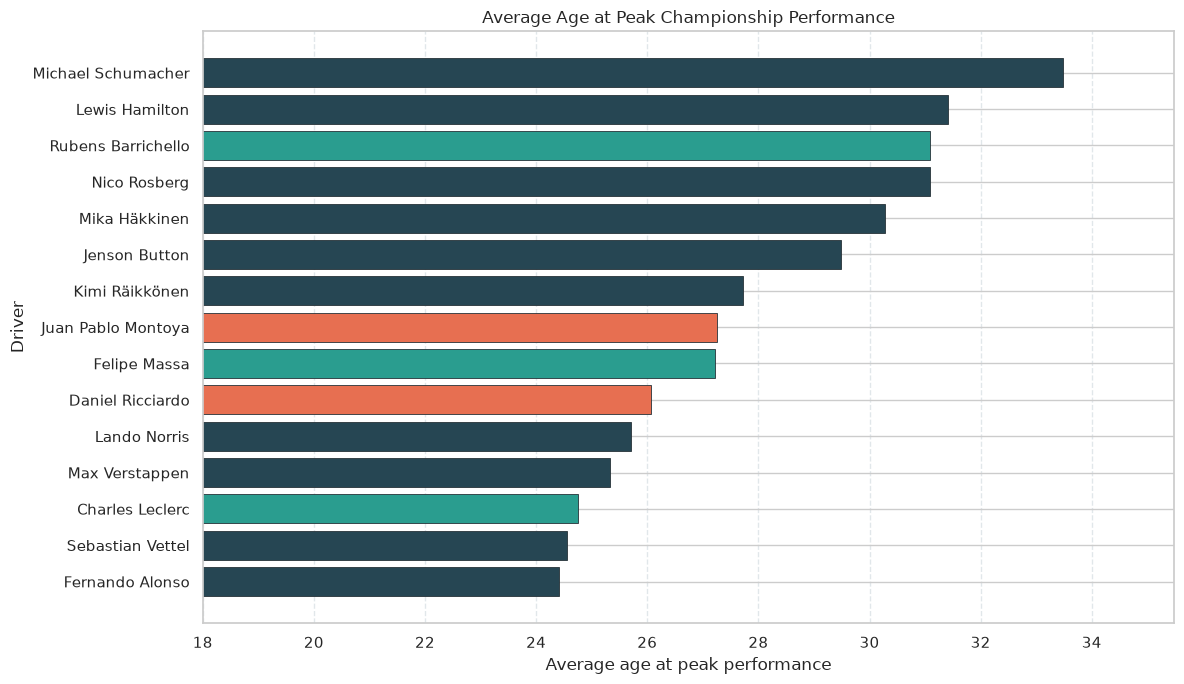

In [24]:
import matplotlib.pyplot as plt

age_plot_data = peak_summary.sort_values(
    "average_age_at_peak",
    ascending=True
)

plt.figure(figsize=(12, 7))

bar_colors = (
    age_plot_data["best_championship_rank"]
    .astype(int)
    .map(RANK_COLORS)
)

plt.barh(
    age_plot_data["full_name"],
    age_plot_data["average_age_at_peak"],
    color=bar_colors,
    edgecolor=PALETTE["edge"],
    linewidth=0.6
)

plt.xlabel("Average age at peak performance")
plt.ylabel("Driver")
plt.title("Average Age at Peak Championship Performance")

plt.xlim(18, age_plot_data["average_age_at_peak"].max() + 2)
plt.grid(axis="x", linestyle="--", color=PALETTE["grid"], alpha=0.7)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 8.6.2 Career Experience at Peak Performance

This chart shows the mean `career_year` across all seasons in which each driver achieved their best recorded championship rank. `career_year` is calendar time elapsed since debut (debut season = 1), not a count of active participation seasons.

For example, Juan Pablo Montoya's two best recorded seasons are career years 2 and 3 (mean 2.5), while Michael Schumacher's five first-place seasons in this dataset are career years 10–14 (mean 12). Career year is therefore a measure of elapsed career time and should not be mistaken for the number of seasons actually raced.

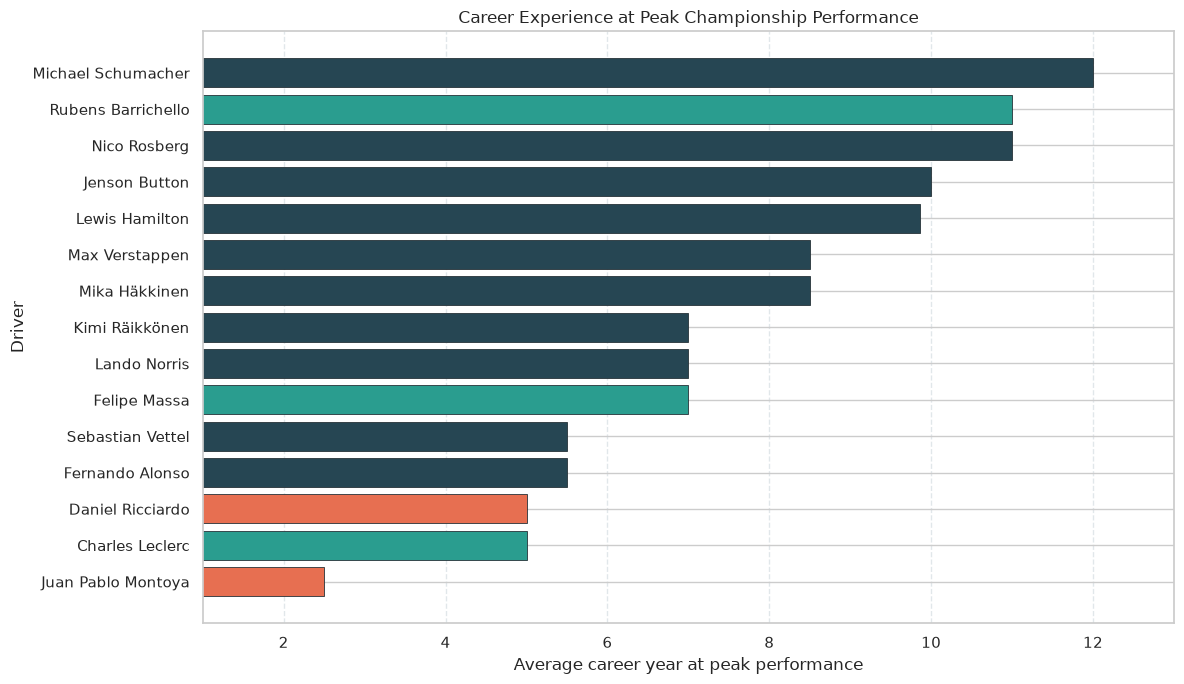

In [25]:
experience_plot_data = peak_summary.sort_values(
    "average_career_year_at_peak",
    ascending=True
)

plt.figure(figsize=(12, 7))

bar_colors = (
    experience_plot_data["best_championship_rank"]
    .astype(int)
    .map(RANK_COLORS)
)

plt.barh(
    experience_plot_data["full_name"],
    experience_plot_data["average_career_year_at_peak"],
    color=bar_colors,
    edgecolor=PALETTE["edge"],
    linewidth=0.6
)
plt.xlabel("Average career year at peak performance")
plt.ylabel("Driver")
plt.title("Career Experience at Peak Championship Performance")

plt.xlim(
    1,
    experience_plot_data["average_career_year_at_peak"].max() + 1
)
plt.grid(axis="x", linestyle="--", color=PALETTE["grid"], alpha=0.7)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 8.6.3 Relationship Between Age and Career Experience at Peak Performance

Each point represents one driver and plots the driver's average age against average `career_year` across all seasons at their best recorded rank. Color indicates the best points-based championship rank.

Age and career year are mathematically related because career year is derived from debut year and season year; they are not independent explanatory variables. Differences between drivers partly reflect different debut ages and the number of elapsed calendar years. This plot is descriptive and does not isolate an effect of age from experience.

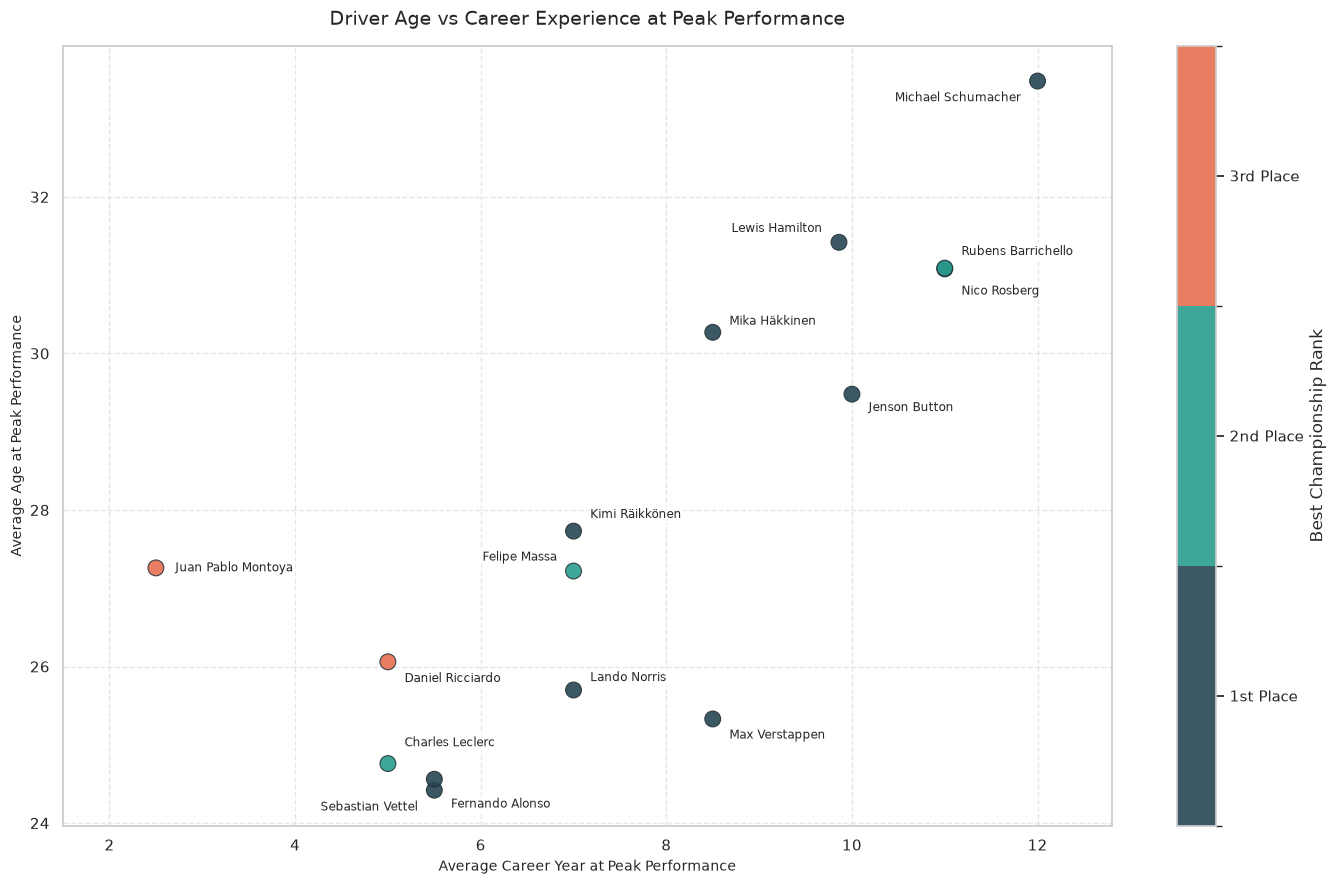

In [26]:
scatter_data = peak_summary.copy()

rank_values = (
    scatter_data["best_championship_rank"].astype(int)
)

if not set(rank_values).issubset(RANK_COLORS):
    raise ValueError("Unexpected championship rank found.")

fig, ax = plt.subplots(figsize=(14, 9))

scatter = ax.scatter(
    scatter_data["average_career_year_at_peak"],
    scatter_data["average_age_at_peak"],
    c=rank_values,
    cmap=RANK_CMAP,
    norm=RANK_NORM,
    s=130,
    alpha=0.9,
    edgecolors=PALETTE["edge"],
    linewidths=0.8,
    zorder=3
)

label_offsets = {
    "Juan Pablo Montoya": (14, 0),
    "Felipe Massa": (-12, 10),
    "Kimi Räikkönen": (12, 12),
    "Mika Häkkinen": (12, 8),
    "Lewis Hamilton": (-12, 10),
    "Jenson Button": (12, -10),
    "Nico Rosberg": (12, -16),
    "Rubens Barrichello": (12, 12),
    "Michael Schumacher": (-12, -12),
    "Charles Leclerc": (12, 15),
    "Fernando Alonso": (12, -10),
    "Sebastian Vettel": (-12, -20),
    "Daniel Ricciardo": (12, -12),
    "Lando Norris": (12, 9),
    "Max Verstappen": (12, -12)
}

for _, row in scatter_data.iterrows():
    name = row["full_name"]
    offset = label_offsets.get(name, (10, 8))

    ax.annotate(
        name,
        (
            row["average_career_year_at_peak"],
            row["average_age_at_peak"]
        ),
        xytext=offset,
        textcoords="offset points",
        fontsize=8.5,
        ha="left" if offset[0] > 0 else "right",
        va="center",
        bbox={
            "boxstyle": "round,pad=0.2",
            "fc": "white",
            "ec": "none",
            "alpha": 0.75
        },
        zorder=4
    )

colorbar = fig.colorbar(
    scatter,
    ax=ax,
    ticks=[1, 2, 3],
    boundaries=[0.5, 1.5, 2.5, 3.5]
)

colorbar.set_label("Best Championship Rank")
colorbar.set_ticklabels([
    "1st Place",
    "2nd Place",
    "3rd Place"
])

ax.set_xlabel(
    "Average Career Year at Peak Performance",
    fontsize=10
)

ax.set_ylabel(
    "Average Age at Peak Performance",
    fontsize=10
)

ax.set_title(
    "Driver Age vs Career Experience at Peak Performance",
    fontsize=14,
    pad=15
)

ax.set_xlim(
    scatter_data["average_career_year_at_peak"].min() - 1,
    scatter_data["average_career_year_at_peak"].max() + 0.8
)

ax.grid(
    True,
    linestyle="--",
    color="#D5DDE2",
    alpha=0.7
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Interpretation of the Age vs Career Experience Plot

The points show substantial variation in both dimensions. Drivers can reach a best recorded rank at similar ages but at different career stages, or at similar career stages but different ages. For example, the saved peak summary places Fernando Alonso's first-place seasons at an average age of 24.42 and mean career year 5.5, whereas Michael Schumacher's recorded first-place seasons average 33.48 years and career year 12.

This should not be read as evidence that age and experience independently affect performance: career year is constructed from calendar time since debut and is therefore related to age. The observed differences may also reflect team and car competitiveness, scoring rules, and the left-censored careers of three drivers.

### 8.6.4 Championship Performance Across Career Years

This heatmap places each driver's season-level championship rank against `career_year`. Each row is a driver and each column is an elapsed calendar year since the driver's debut (debut season = 1). Dark blue, teal, and coral indicate first, second, and third place; light grey represents fourth place or lower. Blank cells indicate that no season record is available for that driver and career year.

The saved peak-season table shows several visible clusters of first-place performance rather than a common career timetable. Sebastian Vettel's four recorded first-place seasons occur in career years 4–7, while Max Verstappen's four occur in years 7–10. Lewis Hamilton's seven first-place seasons are spread from career year 2 through year 14, and Michael Schumacher's five recorded first-place seasons occur in years 10–14. Fernando Alonso's two first-place seasons are consecutive (career years 5–6), as are Mika Häkkinen's (years 8–9).

These clusters illustrate that the duration and timing of a driver's strongest recorded championship rank differ substantially. They do not establish a universal progression: blank cells can reflect missing coverage or seasons without a recorded row, and the careers of Schumacher, Häkkinen, and Barrichello are left-censored by the dataset's 1996 start. The incomplete 2026 season is excluded.


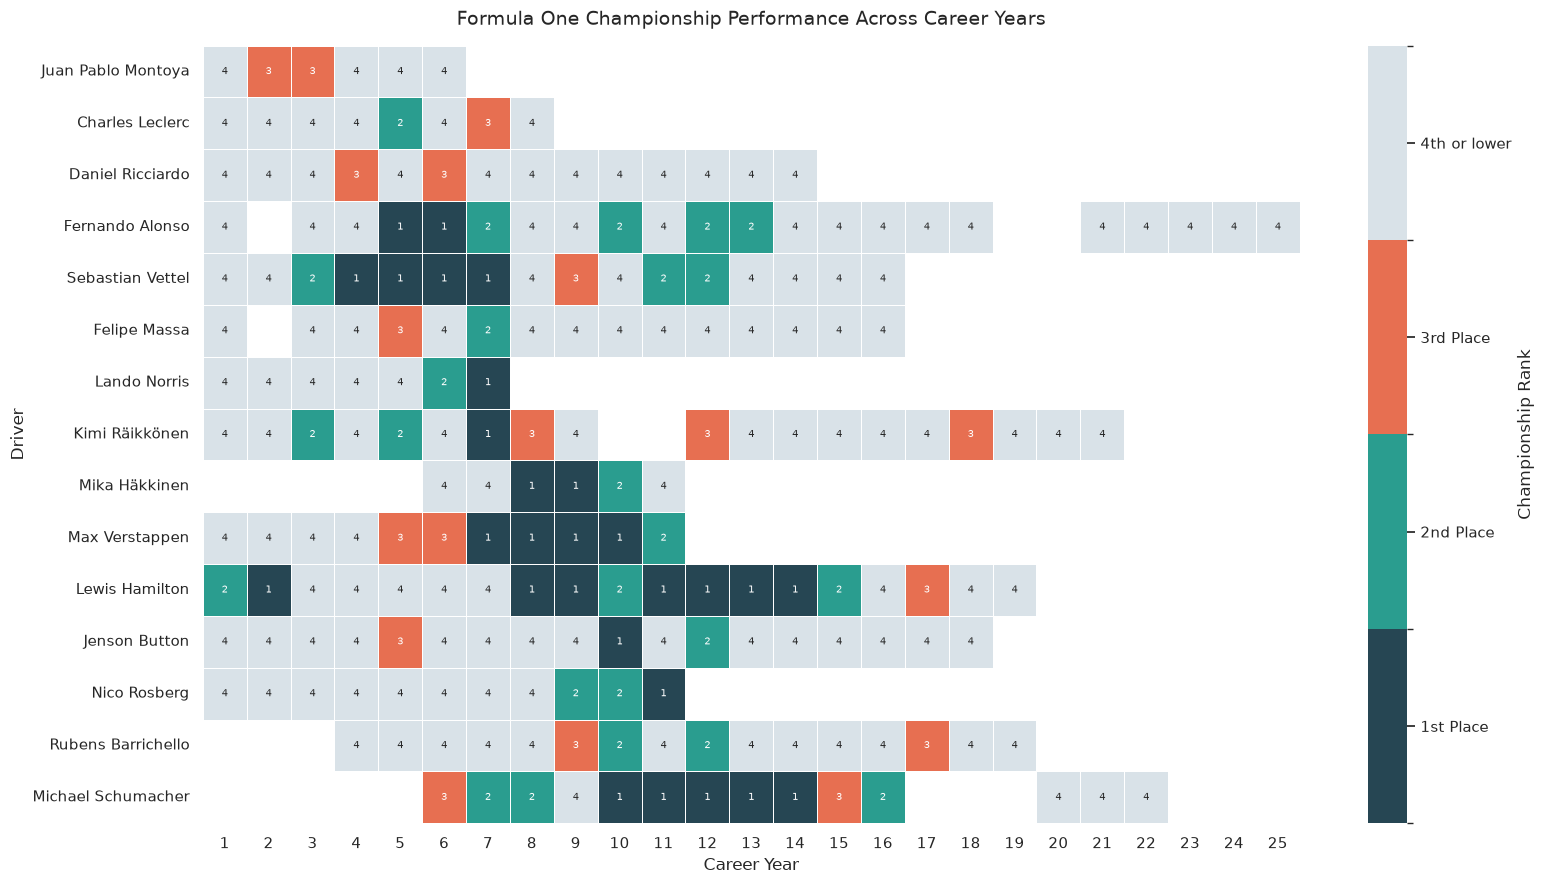

In [27]:
heatmap_source = complete_season_analysis[
    ["full_name", "career_year", "points_rank"]
].copy()


def classify_rank(rank):
    """Group championship rankings into performance categories."""
    if pd.isna(rank):
        return float("nan")

    if rank <= 3:
        return int(rank)

    return 4


heatmap_source["rank_category"] = (
    heatmap_source["points_rank"].apply(classify_rank)
)

career_heatmap = heatmap_source.pivot(
    index="full_name",
    columns="career_year",
    values="rank_category"
)

driver_order = (
    peak_summary.sort_values(
        "average_career_year_at_peak"
    )["full_name"].tolist()
)

max_career_year = int(
    complete_season_analysis["career_year"].max()
)

career_heatmap = career_heatmap.reindex(
    index=driver_order,
    columns=range(1, max_career_year + 1)
)

fig, ax = plt.subplots(
    figsize=(16, 9)
)

sns.heatmap(
    career_heatmap,
    cmap=HEATMAP_CMAP,
    norm=HEATMAP_NORM,
    mask=career_heatmap.isna(),
    annot=True,
    fmt=".0f",
    annot_kws={"size": 7},
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "ticks": [1, 2, 3, 4],
        "label": "Championship Rank"
    },
    ax=ax
)

colorbar = ax.collections[0].colorbar

colorbar.set_ticklabels([
    "1st Place",
    "2nd Place",
    "3rd Place",
    "4th or lower"
])

ax.set_title(
    "Formula One Championship Performance Across Career Years",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Career Year")
ax.set_ylabel("Driver")

plt.tight_layout()
plt.show()

## 9. Early Career vs Later Career

This section examines whether performance in a driver's first three **recorded participation seasons** is associated with performance in subsequent recorded seasons.

The early period is defined by the ordinal sequence of actual driver-season records, not by `career_year` or elapsed calendar time. This distinction matters when a driver misses a season: Fernando Alonso's first three recorded seasons are 2001, 2003, and 2004, while Felipe Massa's are 2002, 2004, and 2005.

The 2026 partial season is excluded. Michael Schumacher, Mika Häkkinen, and Rubens Barrichello are excluded because their true debut seasons predate the dataset and their first three career participation seasons are therefore not fully observed.

For eligible drivers, early seasons are ordinal participation seasons 1–3; later seasons are ordinal participation seasons greater than 3. Rank is the primary outcome. Win and podium rates use race entries as denominators. The analysis is exploratory and does not constitute a prediction model.

### 9.1 Preparing the Early and Later Career Periods

We first remove the incomplete 2026 season, then sort each driver's remaining records chronologically. `career_season_number` assigns 1, 2, 3, and so on to the first, second, third, and subsequent **observed participation seasons**.

Eligibility requires: (1) the actual debut season to be present in the dataset, (2) three early seasons with non-missing championship ranks, and (3) at least one subsequent complete season. This excludes the three drivers whose careers began before 1996, while retaining drivers with a gap between participation seasons.

The early and later filters below both use `career_season_number`, ensuring that the two periods are mutually exclusive and consistently defined.

In [28]:
PARTIAL_SEASONS_FOR_ANALYSIS = [2026]

analysis_period_data = career_timeline.loc[
    ~career_timeline["season"].isin(
        PARTIAL_SEASONS_FOR_ANALYSIS
    )
].copy()

analysis_period_data = analysis_period_data.sort_values(
    ["driver_id", "season"]
).reset_index(drop=True)

if analysis_period_data.duplicated(
    ["driver_id", "season"]
).any():
    raise ValueError(
        "Duplicate driver-season records were found."
    )

# Count the actual recorded participation seasons
analysis_period_data["career_season_number"] = (
    analysis_period_data.groupby("driver_id")["season"]
    .rank(method="dense")
    .astype(int)
)

if analysis_period_data["season"].eq(2026).any():
    raise ValueError("The incomplete 2026 season must be excluded.")

# Check the known participation gaps against the expected first three
# observed seasons. These checks guard against accidentally using
# elapsed calendar career_year values instead.
expected_first_three = {
    "Fernando Alonso": [2001, 2003, 2004],
    "Felipe Massa": [2002, 2004, 2005]
}
for driver_name, expected_seasons in expected_first_three.items():
    observed_seasons = sorted(
        analysis_period_data.loc[
            analysis_period_data["full_name"].eq(driver_name),
            "season"
        ].unique()
    )[:3]
    if observed_seasons != expected_seasons:
        raise ValueError(
            f"Unexpected first three recorded participation seasons "
            f"for {driver_name}: {observed_seasons}; "
            f"expected {expected_seasons}."
        )

early_candidates = analysis_period_data.loc[
    analysis_period_data["career_season_number"] <= 3
].copy()

early_coverage = (
    early_candidates.groupby(
        ["driver_id", "full_name"],
        as_index=False
    )
    .agg(
        early_seasons_observed=("season", "nunique"),
        early_rank_values=("points_rank", "count"),
        early_seasons=(
            "season",
            lambda values: ", ".join(
                str(int(year))
                for year in sorted(values.unique())
            )
        )
    )
)

driver_coverage = (
    analysis_period_data.groupby(
        ["driver_id", "full_name"],
        as_index=False
    )
    .agg(
        debut_year=("debut_year", "first"),
        first_recorded_season=("season", "min"),
        last_recorded_season=("season", "max"),
        total_seasons_observed=("season", "nunique"),
        later_seasons_observed=(
            "career_season_number",
            lambda values: int((values > 3).sum())
        )
    )
)

coverage_summary = driver_coverage.merge(
    early_coverage,
    on=["driver_id", "full_name"],
    how="left",
    validate="one_to_one"
)

coverage_summary["complete_debut_coverage"] = (
    coverage_summary["first_recorded_season"]
    == coverage_summary["debut_year"]
)

coverage_summary["complete_first_three_seasons"] = (
    coverage_summary["early_seasons_observed"].eq(3)
    & coverage_summary["early_rank_values"].eq(3)
)

coverage_summary["has_later_seasons"] = (
    coverage_summary["later_seasons_observed"] > 0
)

coverage_summary["eligible_for_comparison"] = (
    coverage_summary["complete_debut_coverage"]
    & coverage_summary["complete_first_three_seasons"]
    & coverage_summary["has_later_seasons"]
)

eligible_driver_ids = set(
    coverage_summary.loc[
        coverage_summary["eligible_for_comparison"],
        "driver_id"
    ]
)

print(
    "Total selected drivers:",
    coverage_summary["driver_id"].nunique()
)

print(
    "Drivers eligible for comparison:",
    len(eligible_driver_ids)
)

print(
    "Drivers excluded:",
    (~coverage_summary["eligible_for_comparison"]).sum()
)

display(
    coverage_summary[
        [
            "full_name",
            "debut_year",
            "first_recorded_season",
            "early_seasons",
            "early_seasons_observed",
            "later_seasons_observed",
            "complete_debut_coverage",
            "eligible_for_comparison"
        ]
    ].sort_values("full_name").reset_index(drop=True)
)

if len(eligible_driver_ids) < 3:
    raise ValueError(
        "Not enough drivers have complete early and later career data."
    )

Total selected drivers: 15
Drivers eligible for comparison: 12
Drivers excluded: 3


,full_name,debut_year,first_recorded_season,early_seasons,early_seasons_observed,later_seasons_observed,complete_debut_coverage,eligible_for_comparison
0,Charles Leclerc,2018,2018,"2018, 2019, 2020",3,5,True,True
1,Daniel Ricciardo,2011,2011,"2011, 2012, 2013",3,11,True,True
2,Felipe Massa,2002,2002,"2002, 2004, 2005",3,12,True,True
3,Fernando Alonso,2001,2001,"2001, 2003, 2004",3,19,True,True
4,Jenson Button,2000,2000,"2000, 2001, 2002",3,15,True,True
5,Juan Pablo Montoya,2001,2001,"2001, 2002, 2003",3,3,True,True
6,Kimi Räikkönen,2001,2001,"2001, 2002, 2003",3,16,True,True
7,Lando Norris,2019,2019,"2019, 2020, 2021",3,4,True,True
8,Lewis Hamilton,2007,2007,"2007, 2008, 2009",3,16,True,True
9,Max Verstappen,2015,2015,"2015, 2016, 2017",3,8,True,True


### 9.2 Measuring Early-Career Performance

We now analyze each eligible driver's first three Formula One seasons.

For each driver, we calculate:

- Average championship rank across the first three seasons.
- Best championship rank achieved during those seasons.
- Average age during the early-career period.
- Total race wins and podiums.
- Total race entries.
- Win and podium rates.

The average championship rank is our main indicator of early-career performance.

A lower championship rank represents a stronger result. Total points are retained as descriptive information only because Formula One's points-scoring systems have changed over time.

In [29]:
early_career_data = analysis_period_data.loc[
    analysis_period_data["driver_id"].isin(
        eligible_driver_ids
    )
    & analysis_period_data["career_season_number"].between(1, 3)
].copy()

if not early_career_data.groupby("driver_id")["career_season_number"].apply(
    lambda values: set(values) == {1, 2, 3}
).all():
    raise ValueError("Each eligible driver must have exactly participation seasons 1, 2, and 3.")

if early_career_data["points_rank"].isna().any():
    raise ValueError("Early-career records contain missing championship ranks.")

early_career_summary = (
    early_career_data.groupby(
        ["driver_id", "full_name"],
        as_index=False
    )
    .agg(
        early_seasons_observed=("season", "nunique"),
        early_seasons=(
            "season",
            lambda values: ", ".join(
                str(int(year))
                for year in sorted(values.unique())
            )
        ),
        early_average_championship_rank=(
            "points_rank", "mean"
        ),
        early_best_championship_rank=(
            "points_rank", "min"
        ),
        early_average_age=("average_age", "mean"),
        early_total_race_entries=("race_entries", "sum"),
        early_total_wins=("wins", "sum"),
        early_total_podiums=("podiums", "sum"),
        early_total_points=("total_points", "sum")
    )
)

early_career_summary["early_win_rate_pct"] = (
    early_career_summary["early_total_wins"]
    / early_career_summary["early_total_race_entries"]
    * 100
)

early_career_summary["early_podium_rate_pct"] = (
    early_career_summary["early_total_podiums"]
    / early_career_summary["early_total_race_entries"]
    * 100
)

early_career_summary = early_career_summary.sort_values(
    "early_average_championship_rank"
).reset_index(drop=True)

display(early_career_summary.round(2))

,driver_id,full_name,early_seasons_observed,early_seasons,early_average_championship_rank,early_best_championship_rank,early_average_age,early_total_race_entries,early_total_wins,early_total_podiums,early_total_points,early_win_rate_pct,early_podium_rate_pct
0,hamilton,Lewis Hamilton,3,"2007, 2008, 2009",2.67,1.0,23.51,52,11,27,256.0,21.15,51.92
1,montoya,Juan Pablo Montoya,3,"2001, 2002, 2003",4.00,3.0,26.76,50,3,20,163.0,6.00,40.00
2,raikkonen,Kimi Räikkönen,3,"2001, 2002, 2003",6.00,2.0,22.68,50,1,14,124.0,2.00,28.00
3,max_verstappen,Max Verstappen,3,"2015, 2016, 2017",7.67,5.0,18.82,60,3,11,421.0,5.00,18.33
4,vettel,Sebastian Vettel,3,"2007, 2008, 2009",8.00,2.0,21.08,43,5,9,125.0,11.63,20.93
5,leclerc,Charles Leclerc,3,"2018, 2019, 2020",8.33,4.0,21.83,59,2,12,401.0,3.39,20.34
6,norris,Lando Norris,3,"2019, 2020, 2021",8.67,6.0,20.77,60,0,5,306.0,0.00,8.33
7,alonso,Fernando Alonso,3,"2001, 2003, 2004",9.67,4.0,21.57,51,1,8,114.0,1.96,15.69
8,button,Jenson Button,3,"2000, 2001, 2002",10.67,7.0,21.43,51,0,0,28.0,0.00,0.00
9,massa,Felipe Massa,3,"2002, 2004, 2005",12.33,12.0,22.84,53,0,0,27.0,0.00,0.00


### 9.3 Measuring Later-Career Success

The later-career period contains every complete recorded participation season after the first three. Its filter uses `career_season_number > 3`, the complement of the early-period filter.

We summarize average and best championship rank, the number of first-place and top-three ranked seasons, age, race entries, wins, and podiums. Win and podium rates are calculated as total wins or podiums divided by total race entries across the period, multiplied by 100.

These are pooled entry-based rates, not averages of annual percentages. Championship ranks are based on available race points and are not necessarily identical to official classifications where Sprint points or tie-break rules are absent.

In [30]:
later_career_data = analysis_period_data.loc[
    analysis_period_data["driver_id"].isin(
        eligible_driver_ids
    )
    & (analysis_period_data["career_season_number"] > 3)
].copy()


if later_career_data.empty:
    raise ValueError(
        "No later-career records found for eligible drivers."
    )


later_career_summary = (
    later_career_data.groupby(
        ["driver_id", "full_name"],
        as_index=False
    )
    .agg(
        later_seasons_observed=("season", "nunique"),
        later_seasons=(
            "season",
            lambda values: ", ".join(
                str(int(year))
                for year in sorted(values.unique())
            )
        ),
        later_ranked_seasons=("points_rank", "count"),
        later_average_championship_rank=(
            "points_rank", "mean"
        ),
        later_best_championship_rank=(
            "points_rank", "min"
        ),
        later_rank1_seasons=(
            "points_rank",
            lambda values: int((values == 1).sum())
        ),
        later_top3_seasons=(
            "points_rank",
            lambda values: int((values <= 3).sum())
        ),
        later_average_age=("average_age", "mean"),
        later_total_race_entries=("race_entries", "sum"),
        later_total_wins=("wins", "sum"),
        later_total_podiums=("podiums", "sum")
    )
)


if later_career_summary["later_total_race_entries"].le(0).any():
    raise ValueError(
        "Some drivers have no later-career race entries."
    )


later_career_summary["later_win_rate_pct"] = (
    later_career_summary["later_total_wins"]
    / later_career_summary["later_total_race_entries"]
    * 100
)

later_career_summary["later_podium_rate_pct"] = (
    later_career_summary["later_total_podiums"]
    / later_career_summary["later_total_race_entries"]
    * 100
)


later_career_summary = later_career_summary.sort_values(
    "later_average_championship_rank"
).reset_index(drop=True)


display(later_career_summary.round(2))
# Confirm that early and later participation-season records do not overlap.
early_keys = set(
    zip(early_career_data["driver_id"], early_career_data["season"])
)
later_keys = set(
    zip(later_career_data["driver_id"], later_career_data["season"])
)
if early_keys.intersection(later_keys):
    raise ValueError("Early- and later-career periods overlap.")


,driver_id,full_name,later_seasons_observed,later_seasons,later_ranked_seasons,later_average_championship_rank,later_best_championship_rank,later_rank1_seasons,later_top3_seasons,later_average_age,later_total_race_entries,later_total_wins,later_total_podiums,later_win_rate_pct,later_podium_rate_pct
0,max_verstappen,Max Verstappen,8,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",8,2.00,1.0,4,7,24.34,173,68,116,39.31,67.05
1,hamilton,Lewis Hamilton,16,"2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017...",16,3.00,1.0,6,9,33.06,328,94,175,28.66,53.35
2,norris,Lando Norris,4,"2022, 2023, 2024, 2025",4,4.00,1.0,1,2,24.19,92,11,39,11.96,42.39
3,leclerc,Charles Leclerc,5,"2021, 2022, 2023, 2024, 2025",5,4.40,2.0,0,2,25.78,114,6,38,5.26,33.33
4,vettel,Sebastian Vettel,13,"2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017...",13,4.69,1.0,4,7,29.08,257,48,113,18.68,43.97
5,rosberg,Nico Rosberg,8,"2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016",8,5.12,1.0,1,3,27.57,153,23,55,15.03,35.95
6,montoya,Juan Pablo Montoya,3,"2004, 2005, 2006",3,5.67,4.0,0,0,29.74,45,4,10,8.89,22.22
7,raikkonen,Kimi Räikkönen,16,"2004, 2005, 2006, 2007, 2008, 2009, 2012, 2013...",16,6.50,1.0,1,5,33.51,302,20,89,6.62,29.47
8,massa,Felipe Massa,12,"2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013...",12,6.75,2.0,0,2,30.72,218,11,41,5.05,18.81
9,alonso,Fernando Alonso,19,"2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012...",19,6.79,1.0,2,6,33.51,377,31,98,8.22,25.99


### 9.4 Comparing Early-Career Performance with Later Success

The early and later summaries are merged one-to-one by driver. We compare early average championship rank with (1) later average rank and (2) the best rank achieved later.

Because lower numerical ranks indicate stronger performance, a **positive** Spearman coefficient means drivers with weaker (higher-numbered) early ranks tend also to have weaker later ranks. A negative coefficient would indicate that higher early rank numbers tend to accompany lower later rank numbers. The sign must therefore be interpreted with the rank scale in mind.

Spearman's rho describes monotonic association, not predictive accuracy or causation. The small, deliberately selected sample and differences in team/car competitiveness limit generalization.

In [31]:
early_future_comparison = early_career_summary.merge(
    later_career_summary,
    on=["driver_id", "full_name"],
    how="inner",
    validate="one_to_one"
)

early_future_comparison = early_future_comparison.sort_values(
    "early_average_championship_rank"
).reset_index(drop=True)

print(
    "Drivers included in the comparison:",
    len(early_future_comparison)
)

display(early_future_comparison.round(2))


Drivers included in the comparison: 12


,driver_id,full_name,early_seasons_observed,early_seasons,early_average_championship_rank,early_best_championship_rank,early_average_age,early_total_race_entries,early_total_wins,early_total_podiums,...,later_average_championship_rank,later_best_championship_rank,later_rank1_seasons,later_top3_seasons,later_average_age,later_total_race_entries,later_total_wins,later_total_podiums,later_win_rate_pct,later_podium_rate_pct
0,hamilton,Lewis Hamilton,3,"2007, 2008, 2009",2.67,1.0,23.51,52,11,27,...,3.00,1.0,6,9,33.06,328,94,175,28.66,53.35
1,montoya,Juan Pablo Montoya,3,"2001, 2002, 2003",4.00,3.0,26.76,50,3,20,...,5.67,4.0,0,0,29.74,45,4,10,8.89,22.22
2,raikkonen,Kimi Räikkönen,3,"2001, 2002, 2003",6.00,2.0,22.68,50,1,14,...,6.50,1.0,1,5,33.51,302,20,89,6.62,29.47
3,max_verstappen,Max Verstappen,3,"2015, 2016, 2017",7.67,5.0,18.82,60,3,11,...,2.00,1.0,4,7,24.34,173,68,116,39.31,67.05
4,vettel,Sebastian Vettel,3,"2007, 2008, 2009",8.00,2.0,21.08,43,5,9,...,4.69,1.0,4,7,29.08,257,48,113,18.68,43.97
5,leclerc,Charles Leclerc,3,"2018, 2019, 2020",8.33,4.0,21.83,59,2,12,...,4.40,2.0,0,2,25.78,114,6,38,5.26,33.33
6,norris,Lando Norris,3,"2019, 2020, 2021",8.67,6.0,20.77,60,0,5,...,4.00,1.0,1,2,24.19,92,11,39,11.96,42.39
7,alonso,Fernando Alonso,3,"2001, 2003, 2004",9.67,4.0,21.57,51,1,8,...,6.79,1.0,2,6,33.51,377,31,98,8.22,25.99
8,button,Jenson Button,3,"2000, 2001, 2002",10.67,7.0,21.43,51,0,0,...,9.33,1.0,1,3,30.48,258,15,50,5.81,19.38
9,massa,Felipe Massa,3,"2002, 2004, 2005",12.33,12.0,22.84,53,0,0,...,6.75,2.0,0,2,30.72,218,11,41,5.05,18.81


### 9.5 Visualizing Early Career vs Later Career

The following visualizations use the same comparison cohort and the corrected definition: the first three actual recorded participation seasons versus all subsequent complete recorded seasons. The incomplete 2026 season and drivers without complete debut coverage are excluded.

The scatter plot compares average championship rank between periods; the grouped bar charts compare race-entry-based podium and win rates. Lower championship-rank numbers indicate stronger results. These plots are descriptive and should be read alongside the Spearman tests in Section 9.5.4.

**Execution note:** In the supplied notebook, the Section 9 analysis cells have no saved outputs. Their tables, graphs, and correlations must be regenerated by running the notebook with the original source CSV files. The text below explains how to read each plot; it does not claim unobserved numerical findings.


#### 9.5.1 Early Performance vs Later Performance

This scatter plot places each eligible driver's average championship rank in the first three participation seasons on the horizontal axis and average rank in all later complete participation seasons on the vertical axis. The dashed diagonal represents equal average rank across the two periods.

Because lower rank numbers are better, points below the diagonal indicate a numerically stronger average rank in the later period; points above it indicate a weaker later average rank. The distance from the line describes the size of the within-driver difference, not the strength of a cross-driver association.

The distribution of points should be considered together with Spearman's rho in Section 9.5.4. The chart alone cannot establish whether early rank is associated with later rank across drivers, and any observed change may also reflect team and car competitiveness, scoring rules, and different career lengths.


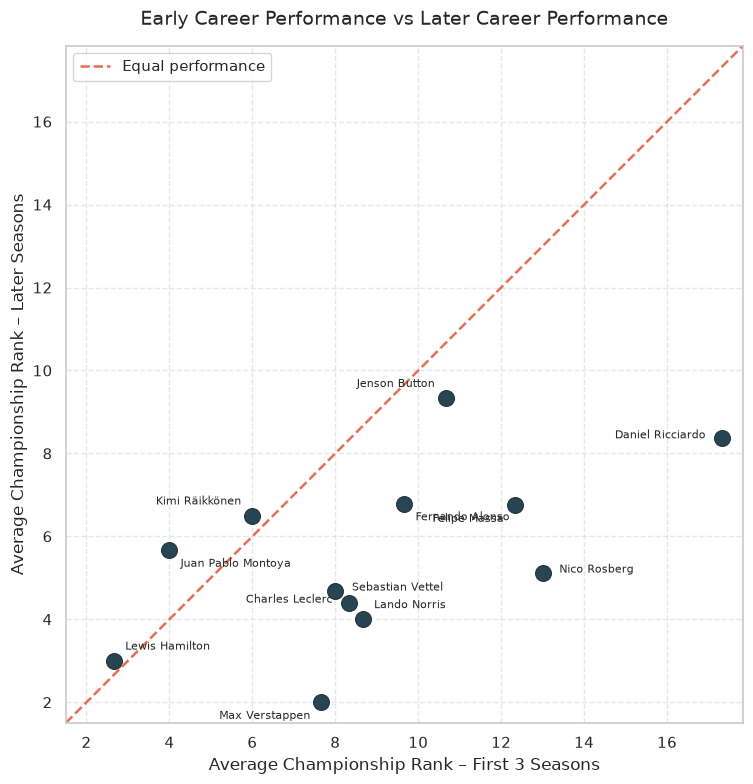

In [32]:
rank_comparison = early_future_comparison.copy()

fig, ax = plt.subplots(figsize=(11, 8))

sns.scatterplot(
    data=rank_comparison,
    x="early_average_championship_rank",
    y="later_average_championship_rank",
    color=PALETTE["rank_1"],
    s=130,
    edgecolor=PALETTE["edge"],
    linewidth=0.8,
    ax=ax
)

lower_limit = min(
    rank_comparison["early_average_championship_rank"].min(),
    rank_comparison["later_average_championship_rank"].min()
) - 0.5

upper_limit = max(
    rank_comparison["early_average_championship_rank"].max(),
    rank_comparison["later_average_championship_rank"].max()
) + 0.5

ax.plot(
    [lower_limit, upper_limit],
    [lower_limit, upper_limit],
    color=PALETTE["highlight"],
    linestyle="--",
    linewidth=1.8,
    label="Equal performance"
)

offsets = [
    (8, 8), (8, -12), (-8, 8), (-8, -12),
    (12, 0), (-12, 0)
]

for i, (_, row) in enumerate(rank_comparison.iterrows()):
    offset = offsets[i % len(offsets)]

    ax.annotate(
        row["full_name"],
        (
            row["early_average_championship_rank"],
            row["later_average_championship_rank"]
        ),
        xytext=offset,
        textcoords="offset points",
        fontsize=8,
        ha="left" if offset[0] > 0 else "right"
    )

ax.set_xlim(lower_limit, upper_limit)
ax.set_ylim(lower_limit, upper_limit)

ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("Average Championship Rank – First 3 Seasons")
ax.set_ylabel("Average Championship Rank – Later Seasons")

ax.set_title(
    "Early Career Performance vs Later Career Performance",
    fontsize=14,
    pad=15
)

ax.legend()
ax.grid(
    linestyle="--",
    color=PALETTE["grid"],
    alpha=0.7
)

plt.tight_layout()
plt.show()

#### 9.5.2 Early Career vs Later Career Podium Rate

This grouped horizontal bar chart compares each driver's podium rate in the first three participation seasons with the rate in subsequent complete seasons. Each rate is calculated as total podium finishes divided by total race entries in that period, multiplied by 100.

Using race entries as the denominator is more informative than comparing raw podium totals because drivers have different numbers of starts. However, the rates remain influenced by machinery, team strength, calendar size, and the level of competition. A higher later-career rate is a descriptive difference, not evidence that experience alone caused improvement.

The supplied notebook has no saved output for this corrected chart, so its driver-level pattern should be interpreted only after the Section 9 cells have been executed.


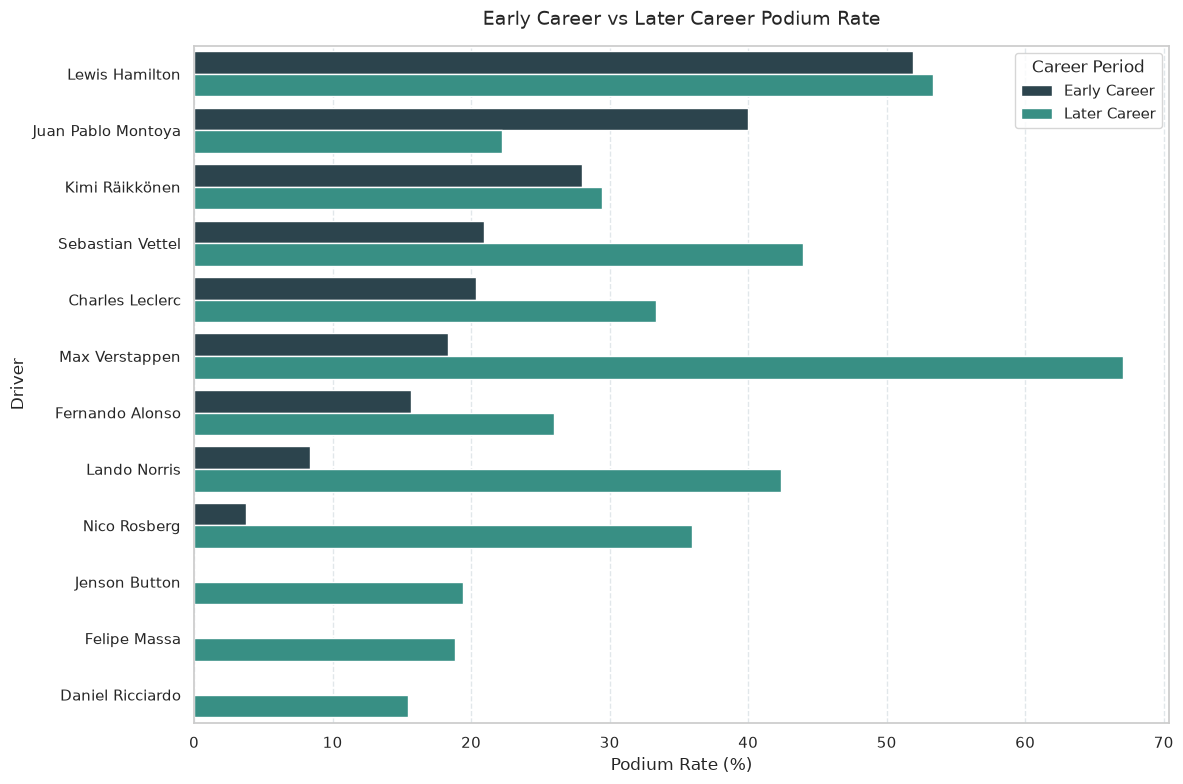

In [33]:
podium_plot_data = early_future_comparison.melt(
    id_vars="full_name",
    value_vars=[
        "early_podium_rate_pct",
        "later_podium_rate_pct"
    ],
    var_name="period",
    value_name="podium_rate_pct"
)

podium_plot_data["period"] = podium_plot_data["period"].map({
    "early_podium_rate_pct": "Early Career",
    "later_podium_rate_pct": "Later Career"
})

podium_order = (
    early_future_comparison.sort_values(
        "early_podium_rate_pct",
        ascending=False
    )["full_name"].tolist()
)

fig, ax = plt.subplots(figsize=(12, 8))

sns.barplot(
    data=podium_plot_data,
    x="podium_rate_pct",
    y="full_name",
    hue="period",
    order=podium_order,
    hue_order=["Early Career", "Later Career"],
    palette=PERIOD_PALETTE,
    errorbar=None,
    ax=ax
)

ax.set_xlabel("Podium Rate (%)")
ax.set_ylabel("Driver")

ax.set_title(
    "Early Career vs Later Career Podium Rate",
    fontsize=14,
    pad=15
)

ax.legend(title="Career Period")

ax.grid(
    axis="x",
    linestyle="--",
    color=PALETTE["grid"],
    alpha=0.7
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 9.5.3 Early Career vs Later Career Win Rate

This grouped horizontal bar chart compares wins per race entry in the first three participation seasons with wins per race entry in subsequent complete seasons. Rates are percentages, calculated from the total wins and total race entries in each period.

The denominator adjustment makes rates more comparable than raw win counts when drivers have different numbers of starts. Nevertheless, changes between periods can reflect car and team competitiveness, calendar format, and the competitive field as well as the driver's career stage.

The supplied notebook has no saved output for this corrected chart. Any driver-level pattern must therefore be assessed after rerunning Section 9 with the original datasets.


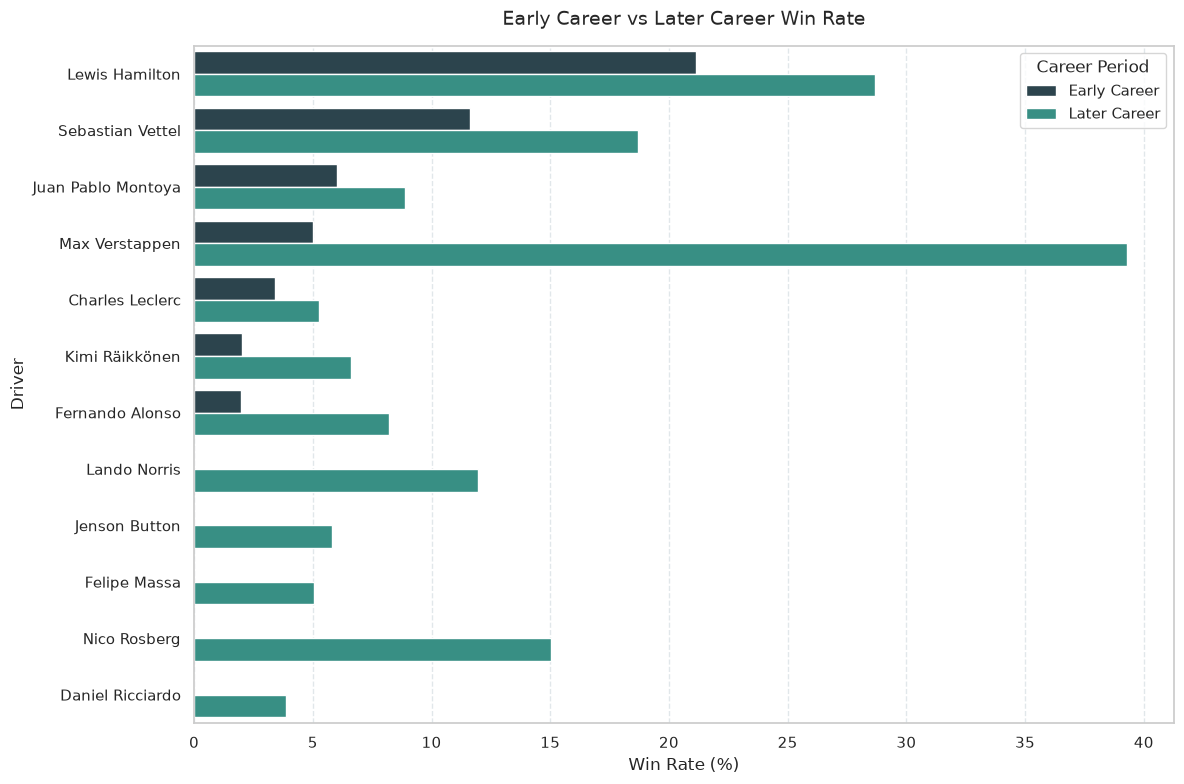

In [34]:
win_plot_data = early_future_comparison.melt(
    id_vars="full_name",
    value_vars=[
        "early_win_rate_pct",
        "later_win_rate_pct"
    ],
    var_name="period",
    value_name="win_rate_pct"
)

win_plot_data["period"] = win_plot_data["period"].map({
    "early_win_rate_pct": "Early Career",
    "later_win_rate_pct": "Later Career"
})

win_order = (
    early_future_comparison.sort_values(
        "early_win_rate_pct",
        ascending=False
    )["full_name"].tolist()
)

fig, ax = plt.subplots(figsize=(12, 8))

sns.barplot(
    data=win_plot_data,
    x="win_rate_pct",
    y="full_name",
    hue="period",
    order=win_order,
    hue_order=["Early Career", "Later Career"],
    palette=PERIOD_PALETTE,
    errorbar=None,
    ax=ax
)

ax.set_xlabel("Win Rate (%)")
ax.set_ylabel("Driver")

ax.set_title(
    "Early Career vs Later Career Win Rate",
    fontsize=14,
    pad=15
)

ax.legend(title="Career Period")

ax.grid(
    axis="x",
    linestyle="--",
    color=PALETTE["grid"],
    alpha=0.7
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 9.5.4 Statistical Relationship Between Early and Later Performance

Spearman's rank correlation is calculated for two pre-specified comparisons: early average championship rank against later average rank, and early average rank against the best later rank. Each test uses complete paired observations and reports the coefficient (rho), two-sided p-value, and number of drivers included.

A positive rho means higher (weaker) early rank numbers tend to accompany higher (weaker) later rank numbers; a negative rho means the direction is reversed. The coefficient describes the direction and strength of a monotonic sample association. The p-value quantifies how compatible the observed coefficient is with a zero-association null under the test assumptions; it does not measure practical importance or the probability that the null is true.

The sample is small and deliberately selected. A non-significant p-value does not prove that no association exists, and a nonzero coefficient does not establish reliable prediction or causation. If either variable is constant or fewer than two complete pairs remain, the correlation is undefined and should be reported as missing rather than interpreted.


In [35]:
from scipy.stats import spearmanr

correlation_tests = [
    (
        "Early average rank vs later average rank",
        "early_average_championship_rank",
        "later_average_championship_rank"
    ),
    (
        "Early average rank vs later best rank",
        "early_average_championship_rank",
        "later_best_championship_rank"
    )
]

correlation_results = []

for comparison_name, early_col, later_col in correlation_tests:
    valid_data = early_future_comparison[
        [early_col, later_col]
    ].dropna()

    n = len(valid_data)

    # Spearman's rho is undefined with fewer than two pairs or
    # when either variable has no variation.
    if (
        n < 2
        or valid_data[early_col].nunique() < 2
        or valid_data[later_col].nunique() < 2
    ):
        rho = float("nan")
        p_value = float("nan")
    else:
        result = spearmanr(
            valid_data[early_col],
            valid_data[later_col],
            alternative="two-sided"
        )
        rho = result.statistic
        p_value = result.pvalue

    correlation_results.append({
        "comparison": comparison_name,
        "spearman_rho": rho,
        "p_value_two_sided": p_value,
        "drivers_analyzed": n
    })

statistical_results = pd.DataFrame(correlation_results)

display(statistical_results.round(4))


,comparison,spearman_rho,p_value_two_sided,drivers_analyzed
0,Early average rank vs later average rank,0.5804,0.0479,12
1,Early average rank vs later best rank,0.1418,0.6602,12


## 10. Main Findings

### 10.1 Age and career experience at peak championship rank

The saved `peak_summary` contains 15 drivers and 36 driver-season records at each driver's best recorded championship rank. Ten drivers' best recorded rank is first place, three drivers' best rank is second, and two drivers' best rank is third.

Among the 10 drivers whose best recorded rank is first place, the mean of their **driver-level average ages across all first-place seasons** is approximately **28.3 years**. This is a summary across drivers and across all seasons tied at each driver's best rank; it is not a single age at which drivers generally first peak. The first recorded first-place season ranges from approximately **23.0 years** for Sebastian Vettel to **31.5 years** for Michael Schumacher. Lewis Hamilton's first recorded first-place season is approximately 23.5 years old, although his average age across all seven first-place seasons is approximately 31.4 years.

The career-stage measures also differ. The first recorded first-place season ranges from career year 2 for Lewis Hamilton to career year 10 for Michael Schumacher. Across all first-place seasons, the driver-level average career year ranges from 5.5 for Fernando Alonso and Sebastian Vettel to 12.0 for Michael Schumacher. Here, `career_year` is elapsed calendar time since debut, not a count of active participation seasons.

### 10.2 Differences and sustained performance

The number of recorded seasons at the best rank varies substantially. Lewis Hamilton has seven first-place seasons in the available complete-season data, Michael Schumacher five, and Sebastian Vettel and Max Verstappen four each. Fernando Alonso and Mika Häkkinen have two each. Several other drivers have one. These counts describe repeated achievement of the best recorded rank, not necessarily an uninterrupted peak or the entirety of each driver's career.

The heatmap and peak table show distinct career patterns: Vettel's first-place seasons cluster in career years 4–7, Verstappen's in years 7–10, Hamilton's are spread from years 2–14, and Schumacher's occur in years 10–14. The timing and duration of peak championship results therefore vary rather than following one common career timetable.

### 10.3 Early-career association with later results

The corrected Section 9 code defines early career as the first three actual recorded participation seasons and later career as all subsequent complete recorded seasons. It excludes 2026 and drivers whose debut seasons predate the dataset coverage. However, the supplied notebook contains no saved outputs for the corrected Section 9 cells, and the original source CSV files were not included with the uploaded materials.

Consequently, no corrected early/later comparison table, graph, Spearman coefficient, p-value, or sample size can be reported from this notebook version. The earlier coefficients from the superseded filter are intentionally not repeated or treated as evidence. Run Section 9 with the original datasets before making an empirical claim about early-career association.

## 11. Answer to the Research Question

For the peak-performance part, the available complete-season records do not identify one universal age or career year. Among drivers whose best recorded rank is first place, the mean of the driver-level average ages across their first-place seasons is approximately 28.3 years, but first recorded first-place seasons range from about 23.0 to 31.5 years. The first recorded career year at that rank ranges from year 2 to year 10. These differences, together with the varying duration of repeated first-place seasons, indicate substantial driver-to-driver variation rather than a single typical peak point. Age and elapsed career year are related measures, not independent explanations.

For the early-career part, the notebook now contains a consistent method for comparing the first three actual participation seasons with subsequent seasons. However, because the corrected Section 9 cells have not been executed against the original CSV files, this version cannot yet establish whether early championship results are associated with later success. No conclusion should be drawn from the old, superseded correlation values. Once the corrected results are generated, Spearman's rho, its two-sided p-value, and the number of drivers should be interpreted together, with due regard for the small selected sample.

## 12. Limitations of the Analysis

- **Dataset coverage:** The race-results dataset begins in 1996, so earlier career seasons are not represented.
- **Left-censored careers:** Michael Schumacher (1991 debut), Mika Häkkinen (1991), and Rubens Barrichello (1993) have incomplete career coverage. They remain in the peak-performance analysis where recorded data permits, but are excluded from the early-career comparison because their true first three participation seasons cannot be observed.
- **Partial 2026 season:** The 2026 season is incomplete and is excluded from complete-season peak comparisons and the early/later analysis.
- **Sprint points:** The source results may omit Sprint race points. `points_rank` is retained as a ranking based on available race points; missing Sprint points are not estimated or added.
- **Scoring and calendar changes:** Points systems, race formats, and the number of events per season have changed, limiting comparisons of raw points and entry-based rates across eras.
- **Team and car competitiveness:** Championship rank, wins, and podiums reflect the combined driver, team, and car package. The analysis cannot isolate driver ability from machinery and team context.
- **Selected sample:** The 15 drivers form a deliberately selected sample rather than a random or representative sample of all Formula One drivers.
- **Partial debut seasons:** Drivers who debuted partway through a season may have fewer race entries in their first participation season. This can affect entry-based early-career rates.
- **Observational design:** The analysis describes associations and career patterns. It cannot establish causation or individual predictive accuracy.
- **Age and career experience:** `career_year` is calculated from season year and debut year. It is mathematically related to age and should not be treated as an independent factor.
- **Ranking construction:** `points_rank` ranks the available season points across the drivers present in the source dataset. It does not apply official championship tie-break procedures. Tied totals may therefore receive the same rank, and omitted Sprint points may alter some positions.
- **Early/later sample size:** The early-career comparison uses only drivers with complete debut coverage, three ranked early participation seasons, and at least one later complete season. The resulting sample is small, limiting statistical power and generalizability.

## 13. Final Conclusion

The peak-performance analysis shows that the strongest recorded championship results occur at different ages and stages of Formula One careers. The average age across drivers' first-place seasons is approximately 28.3 years, but that aggregate conceals a wide range in the age and career year of the first recorded championship-leading season. Some drivers reached first place early and others later, while the number of seasons spent at that best rank also varies considerably. The evidence therefore supports a heterogeneous view of peak performance, not a universal age or experience threshold.

The early-career question requires a separate and carefully defined comparison. This notebook now distinguishes actual participation seasons from elapsed calendar career years, which is essential for drivers with gaps in their participation histories. Yet the corrected comparison has not been executed because the original CSV datasets were not supplied with this notebook. Its association statistics must be regenerated before the project can answer whether early results are related to subsequent career success.

Overall, the project provides descriptive evidence about the diversity of drivers' peak championship careers and a reproducible framework for examining early-to-later career associations. Its conclusions remain bounded by the dataset's historical coverage, points-ranking construction, changing competitive conditions, and small selected sample. The findings should be understood as exploratory associations within the available records, not as causal explanations or predictions of individual careers.
